In [ ]:

import zipfile
import glob
import os

zip_files = glob.glob('/content/data_uts_ml*.zip')

print(zip_files)


['/content/data_uts_ml-20261116T111934Z-1-001.zip']


In [ ]:

zip_path = zip_files[0]

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

print("Dataset berhasil diekstrak!")


Dataset berhasil diekstrak!


In [ ]:

for root, dirs, files in os.walk('/content/dataset'):
    for file in files:
        print(file)


regresi_train.csv.gz
kamus_data.md
regresi_test.csv.gz
klasifikasi_test.csv.gz
klasifikasi_train.csv.gz
clustering.csv.gz


In [ ]:

import pandas as pd
import glob
import os

# Mencari file dataset
train_path = glob.glob(
    '/content/dataset/**/regresi_train.csv.gz',
    recursive=True
)[0]

test_path = glob.glob(
    '/content/dataset/**/regresi_test.csv.gz',
    recursive=True
)[0]

# Membaca dataset
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

print("DATA TRAINING")
print(df_train.shape)

print("\nDATA TESTING")
print(df_test.shape)


DATA TRAINING
(250000, 77)

DATA TESTING
(60000, 76)


In [ ]:

# Melihat 5 data pertama
df_train.head()


,id_paket,tgl_pickup,jam_pickup,layanan,mitra_kurir,hub_asal,kota_asal,pulau_tujuan,kota_tujuan,jarak_km,...,f42,f43,f44,f45,f46,f47,f48,f49,f50,durasi_jam
0,P24198861,2025-03-13,10,ekspres,K07,JKT,KA01,Jawa,KT099,1077.6,...,0.683,0.644,3.957,1.0,3.0,-0.207,0.721,0.661,3.760,40.4
1,P44313480,2025-06-24,9,reguler,K05,SBY,KA09,Jawa,KT101,829.3,...,-0.521,0.011,0.429,0.0,2.0,0.890,0.065,0.232,1.866,78.7
2,P18332724,2025-05-07,11,kargo,K03,JKT,KA02,Jawa,KT066,758.6,...,-1.004,0.506,0.795,0.0,2.0,-2.769,-1.031,0.777,2.809,101.3
3,P85422083,2025-05-19,14,ekspres,K03,MKS,KA28,Sulawesi,KT273,396.2,...,0.240,0.721,1.118,1.0,7.0,2.163,-1.766,0.275,1.498,60.3
4,P60211760,2025-04-29,7,kargo,K07,SMG,KA20,Jawa,KT066,254.6,...,0.287,0.734,1.899,0.0,4.0,0.203,-0.886,0.180,0.512,63.1


In [ ]:

# Melihat seluruh nama kolom
print("DAFTAR SELURUH KOLOM:")
for kolom in df_train.columns:
    print(kolom)

print("\nJUMLAH KOLOM:", len(df_train.columns))

print("\nINFORMASI TARGET:")
print(df_train['durasi_jam'].describe())


DAFTAR SELURUH KOLOM:
id_paket
tgl_pickup
jam_pickup
layanan
mitra_kurir
hub_asal
kota_asal
pulau_tujuan
kota_tujuan
jarak_km
berat_kg
volume_liter
jumlah_item
nilai_barang
asuransi
cod
alamat_skor
pengalaman_kurir_bulan
rating_penjual
umur_akun_penjual_hari
volume_penjual_30h
antrean_hub_asal
indeks_kemacetan
hujan_asal_mm
hujan_tujuan_mm
jumlah_scan
f01
f02
f03
f04
f05
f06
f07
f08
f09
f10
f11
f12
f13
f14
f15
f16
f17
f18
f19
f20
f21
f22
f23
f24
f25
f26
f27
f28
f29
f30
f31
f32
f33
f34
f35
f36
f37
f38
f39
f40
f41
f42
f43
f44
f45
f46
f47
f48
f49
f50
durasi_jam

JUMLAH KOLOM: 77

INFORMASI TARGET:
count    250000.000000
mean         77.838195
std         207.656270
min          11.600000
25%          45.600000
50%          61.700000
75%          85.300000
max       25452.000000
Name: durasi_jam, dtype: float64


In [ ]:

# DATA AUDIT - REGRESSION

# 1. Memeriksa tipe data
print("=== TIPE DATA ===")
print(df_train.dtypes)

# 2. Memeriksa data kosong
print("\n=== DATA KOSONG ===")
print(df_train.isnull().sum().sort_values(ascending=False).head(20))

# 3. Memeriksa data duplikat
print("\n=== DATA DUPLIKAT ===")
print("Jumlah baris duplikat:", df_train.duplicated().sum())

# 4. Memeriksa distribusi target
print("\n=== DISTRIBUSI DURASI ===")
print(df_train['durasi_jam'].describe())

# 5. Memeriksa tanggal pickup
print("\n=== RENTANG TANGGAL ===")
print(df_train['tgl_pickup'].min())
print(df_train['tgl_pickup'].max())


=== TIPE DATA ===
id_paket        object
tgl_pickup      object
jam_pickup       int64
layanan         object
mitra_kurir     object
                ...   
f47            float64
f48            float64
f49            float64
f50            float64
durasi_jam     float64
Length: 77, dtype: object

=== DATA KOSONG ===
berat_kg                  13897
tgl_pickup                    0
jam_pickup                    0
layanan                       0
id_paket                      0
mitra_kurir                   0
hub_asal                      0
pulau_tujuan                  0
kota_asal                     0
kota_tujuan                   0
jarak_km                      0
volume_liter                  0
jumlah_item                   0
nilai_barang                  0
asuransi                      0
cod                           0
alamat_skor                   0
pengalaman_kurir_bulan        0
rating_penjual                0
umur_akun_penjual_hari        0
dtype: int64

=== DATA DUPLIKAT ===
Jumlah

In [ ]:

# PEMERIKSAAN LANJUTAN DATA AUDIT

# 1. Semua kolom yang memiliki data kosong
print("=== DATA KOSONG ===")
missing = df_train.isnull().sum()
print(missing[missing > 0])

# 2. Persentase data kosong
print("\n=== PERSENTASE DATA KOSONG ===")
print((missing[missing > 0] / len(df_train) * 100).round(2))

# 3. Memeriksa target kosong
print("\n=== TARGET KOSONG ===")
print(df_train['durasi_jam'].isnull().sum())

# 4. Memeriksa 10 durasi pengiriman terbesar
print("\n=== 10 DURASI TERBESAR ===")
print(
    df_train.nlargest(10, 'durasi_jam')[
        ['id_paket', 'tgl_pickup', 'layanan',
         'pulau_tujuan', 'durasi_jam']
    ]
)


=== DATA KOSONG ===
berat_kg    13897
dtype: int64

=== PERSENTASE DATA KOSONG ===
berat_kg    5.56
dtype: float64

=== TARGET KOSONG ===
0

=== 10 DURASI TERBESAR ===
         id_paket  tgl_pickup  layanan pulau_tujuan  durasi_jam
84362   P40474529  2025-07-04  reguler         Jawa     25452.0
108275  P62729634  2025-02-06  ekspres         Jawa     25020.0
98789   P12077092  2025-03-03    hemat         Jawa     16650.0
142557  P97171338  2025-01-16    hemat        Papua     16284.0
62562   P34488358  2025-08-10    hemat   Kalimantan     13914.0
63531   P51550495  2025-08-28    hemat         Jawa     13812.0
207233  P30815212  2025-04-26    hemat         Jawa     13746.0
205666  P76218261  2025-06-23    kargo        Papua     13560.0
146636  P28725772  2025-07-26    hemat         Jawa     13482.0
237355  P58123091  2025-08-13    hemat     Sulawesi     12582.0


In [ ]:

# ANALISIS NILAI EKSTREM

print("=== PERSENTIL DURASI ===")
print(df_train['durasi_jam'].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.999, 1.00]
))

print("\n=== JUMLAH DURASI DI ATAS 7 HARI ===")
print((df_train['durasi_jam'] > 168).sum())

print("\n=== JUMLAH DURASI DI ATAS 30 HARI ===")
print((df_train['durasi_jam'] > 720).sum())

print("\n=== PEMERIKSAAN JUMLAH SCAN ===")
print(df_train['jumlah_scan'].describe())


=== PERSENTIL DURASI ===
0.500       61.700
0.750       85.300
0.900      117.800
0.950      145.800
0.990      224.701
0.999     3054.018
1.000    25452.000
Name: durasi_jam, dtype: float64

=== JUMLAH DURASI DI ATAS 7 HARI ===
7480

=== JUMLAH DURASI DI ATAS 30 HARI ===
370

=== PEMERIKSAAN JUMLAH SCAN ===
count    250000.000000
mean          9.651072
std           5.625028
min           1.000000
25%           6.000000
50%           8.000000
75%          12.000000
max          97.000000
Name: jumlah_scan, dtype: float64


In [ ]:
import glob

kamus_path = glob.glob(
    '/content/dataset/**/kamus_data.md',
    recursive=True
)[0]

with open(kamus_path, 'r', encoding='utf-8') as file:
    print(file.read())

# Kamus data UTS Machine Learning

Data latih regresi dan klasifikasi ditarik pada **31 Agustus 2025**. Data uji mencakup
1 September sampai 31 Oktober 2025. Semua kelompok menerima data yang sama.

## Tugas 1: regresi_train.csv.gz dan regresi_test.csv.gz

Satu baris per paket. Prediksi dibuat saat paket diambil kurir.

| Kolom | Keterangan |
| --- | --- |
| id_paket | ID paket |
| tgl_pickup, jam_pickup | Tanggal dan jam paket diambil kurir |
| layanan | Jenis layanan pengiriman |
| mitra_kurir | Mitra kurir yang mengantar |
| hub_asal, kota_asal | Hub penyortiran dan kota asal |
| pulau_tujuan, kota_tujuan | Pulau dan kota tujuan |
| jarak_km | Jarak rute menurut sistem (km) |
| berat_kg | Berat yang dideklarasikan penjual (kg) |
| volume_liter, jumlah_item, nilai_barang | Volume, jumlah barang, dan nilai barang (rupiah) |
| asuransi, cod | 1 jika diasuransikan, 1 jika bayar di tempat |
| alamat_skor | Skor kelengkapan alamat penerima (0-1) |
| pengalaman_kurir_bulan | Pengalaman kur

In [ ]:
import glob

# Mencari semua file berformat .csv atau .gz di direktori saat ini dan sub-direktorinya
print("File CSV / GZ yang ditemukan:")
print(glob.glob('**/*.csv', recursive=True))
print(glob.glob('**/*.gz', recursive=True))
print(glob.glob('/content/**/*.*', recursive=True)) # atau cek root /content jika di Google Colab

File CSV / GZ yang ditemukan:
['sample_data/california_housing_train.csv', 'sample_data/mnist_test.csv', 'sample_data/california_housing_test.csv', 'sample_data/mnist_train_small.csv']
['dataset/data_uts_ml/regresi_train.csv.gz', 'dataset/data_uts_ml/regresi_test.csv.gz', 'dataset/data_uts_ml/klasifikasi_test.csv.gz', 'dataset/data_uts_ml/klasifikasi_train.csv.gz', 'dataset/data_uts_ml/clustering.csv.gz']
['/content/data_uts_ml-20261116T111934Z-1-001.zip', '/content/dataset/data_uts_ml/regresi_train.csv.gz', '/content/dataset/data_uts_ml/kamus_data.md', '/content/dataset/data_uts_ml/regresi_test.csv.gz', '/content/dataset/data_uts_ml/klasifikasi_test.csv.gz', '/content/dataset/data_uts_ml/klasifikasi_train.csv.gz', '/content/dataset/data_uts_ml/clustering.csv.gz', '/content/sample_data/anscombe.json', '/content/sample_data/README.md', '/content/sample_data/california_housing_train.csv', '/content/sample_data/mnist_test.csv', '/content/sample_data/california_housing_test.csv', '/content

In [ ]:
import pandas as pd
import numpy as np

# Load dataset train regresi dengan path yang benar
train_path = 'dataset/data_uts_ml/regresi_train.csv.gz'
train_df = pd.read_csv(train_path)

print("=== UKURAN DATASET ===")
print(train_df.shape)

print("\n=== INFORMASI KOLOM & TIPE DATA ===")
print(train_df.info())

print("\n=== 5 BARIS PERTAMA ===")
display(train_df.head())

print("\n=== STATISTIK TARGET (durasi_jam) ===")
print(train_df['durasi_jam'].describe())

# Cek korelasi numerik untuk mendeteksi potensi data leakage
if 'durasi_jam' in train_df.columns:
    numeric_cols = train_df.select_dtypes(include=[np.number]).columns
    correlations = train_df[numeric_cols].corr()['durasi_jam'].sort_values(ascending=False)
    print("\n=== KORELASI FITUR NUMERIK DENGAN durasi_jam ===")
    print(correlations)

=== UKURAN DATASET ===
(250000, 77)

=== INFORMASI KOLOM & TIPE DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 77 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id_paket                250000 non-null  object 
 1   tgl_pickup              250000 non-null  object 
 2   jam_pickup              250000 non-null  int64  
 3   layanan                 250000 non-null  object 
 4   mitra_kurir             250000 non-null  object 
 5   hub_asal                250000 non-null  object 
 6   kota_asal               250000 non-null  object 
 7   pulau_tujuan            250000 non-null  object 
 8   kota_tujuan             250000 non-null  object 
 9   jarak_km                250000 non-null  float64
 10  berat_kg                236103 non-null  float64
 11  volume_liter            250000 non-null  float64
 12  jumlah_item             250000 non-null  int64  
 13  n

,id_paket,tgl_pickup,jam_pickup,layanan,mitra_kurir,hub_asal,kota_asal,pulau_tujuan,kota_tujuan,jarak_km,...,f42,f43,f44,f45,f46,f47,f48,f49,f50,durasi_jam
0,P24198861,2025-03-13,10,ekspres,K07,JKT,KA01,Jawa,KT099,1077.6,...,0.683,0.644,3.957,1.0,3.0,-0.207,0.721,0.661,3.760,40.4
1,P44313480,2025-06-24,9,reguler,K05,SBY,KA09,Jawa,KT101,829.3,...,-0.521,0.011,0.429,0.0,2.0,0.890,0.065,0.232,1.866,78.7
2,P18332724,2025-05-07,11,kargo,K03,JKT,KA02,Jawa,KT066,758.6,...,-1.004,0.506,0.795,0.0,2.0,-2.769,-1.031,0.777,2.809,101.3
3,P85422083,2025-05-19,14,ekspres,K03,MKS,KA28,Sulawesi,KT273,396.2,...,0.240,0.721,1.118,1.0,7.0,2.163,-1.766,0.275,1.498,60.3
4,P60211760,2025-04-29,7,kargo,K07,SMG,KA20,Jawa,KT066,254.6,...,0.287,0.734,1.899,0.0,4.0,0.203,-0.886,0.180,0.512,63.1



=== STATISTIK TARGET (durasi_jam) ===
count    250000.000000
mean         77.838195
std         207.656270
min          11.600000
25%          45.600000
50%          61.700000
75%          85.300000
max       25452.000000
Name: durasi_jam, dtype: float64

=== KORELASI FITUR NUMERIK DENGAN durasi_jam ===
durasi_jam                1.000000
jumlah_scan               0.188725
f04                       0.102651
jarak_km                  0.096318
f05                       0.079445
                            ...   
f10                      -0.003612
f21                      -0.003715
rating_penjual           -0.005175
pengalaman_kurir_bulan   -0.008381
alamat_skor              -0.027897
Name: durasi_jam, Length: 69, dtype: float64


In [ ]:
import pandas as pd
import numpy as np

# Load dataset
train_df = pd.read_csv('dataset/data_uts_ml/regresi_train.csv.gz')

# 1. Konversi tgl_pickup ke datetime
train_df['tgl_pickup'] = pd.to_datetime(train_df['tgl_pickup'])
print("Rentang Tanggal Pickup:", train_df['tgl_pickup'].min(), "s/d", train_df['tgl_pickup'].max())

# 2. Cek Missing Values
print("\nJumlah Missing Values per Kolom:")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

# Imputasi sederhana untuk berat_kg menggunakan median
train_df['berat_kg'] = train_df['berat_kg'].fillna(train_df['berat_kg'].median())

# 3. Analisis Outlier durasi_jam (misal filter durasi yang tidak masuk akal atau > kuantil 99.5)
upper_limit = train_df['durasi_jam'].quantile(0.995)
print(f"\nBatas Kuantil 99.5 untuk durasi_jam: {upper_limit:.2f} jam")
# Kita bisa lihat berapa banyak baris yang anomali ekstrem
print(f"Jumlah baris dengan durasi > 1000 jam: {(train_df['durasi_jam'] > 1000).sum()}")

# 4. Contoh Time-Based Split (Misal: Train sebelum Agustus 2025, Validasi di Agustus 2025)
train_df['bulan'] = train_df['tgl_pickup'].dt.to_period('M')
print("\nDistribusi Data per Bulan:")
print(train_df['bulan'].value_counts().sort_index())

Rentang Tanggal Pickup: 2025-01-01 00:00:00 s/d 2025-08-31 00:00:00

Jumlah Missing Values per Kolom:
berat_kg    13897
dtype: int64

Batas Kuantil 99.5 untuk durasi_jam: 274.50 jam
Jumlah baris dengan durasi > 1000 jam: 370

Distribusi Data per Bulan:
bulan
2025-01    29985
2025-02    27556
2025-03    32829
2025-04    26244
2025-05    32841
2025-06    31941
2025-07    34436
2025-08    34168
Freq: M, Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

# 1. Menyiapkan Fitur & Membersihkan Outlier Ekstrem Target
df_model = train_df.copy()

# Imputasi berat_kg
df_model['berat_kg'] = df_model['berat_kg'].fillna(df_model['berat_kg'].median())

# Filter outlier ekstrem durasi_jam (ambil yang <= 1000 jam agar model stabil)
df_model = df_model[df_model['durasi_jam'] <= 1000].reset_index(drop=True)

# 2. Time-Based Split: Train (Jan - Jul 2025), Validasi (Agustus 2025)
train_split = df_model[df_model['tgl_pickup'] < '2025-08-01']
val_split = df_model[df_model['tgl_pickup'] >= '2025-08-01']

print(f"Jumlah data train (Jan-Jul): {len(train_split)}")
print(f"Jumlah data validasi (Agustus): {len(val_split)}")

# 3. Menentukan Fitur yang Digunakan
drop_cols = ['id_paket', 'tgl_pickup', 'durasi_jam', 'bulan']
feature_cols = [col for col in train_split.columns if col not in drop_cols]

# Mengubah kolom kategorikal menjadi tipe category untuk LightGBM
cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
for col in cat_cols:
    train_split[col] = train_split[col].astype('category')
    val_split[col] = val_split[col].astype('category')

X_train = train_split[feature_cols]
y_train = train_split['durasi_jam']
X_val = val_split[feature_cols]
y_val = val_split['durasi_jam']

print(f"Jumlah fitur yang digunakan: {len(feature_cols)}")

Jumlah data train (Jan-Jul): 215514
Jumlah data validasi (Agustus): 34116
Jumlah fitur yang digunakan: 74


/tmp/ipykernel_621/503503533.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_split[col] = train_split[col].astype('category')
/tmp/ipykernel_621/503503533.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val_split[col] = val_split[col].astype('category')
/tmp/ipykernel_621/503503533.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pyda

In [ ]:
import lightgbm as lgb
import numpy as np

# Fungsi untuk menghitung Pinball Loss
def pinball_loss(y_true, y_pred, quantile):
    diff = y_true - y_pred
    return np.mean(np.maximum(quantile * diff, (quantile - 1) * diff))

# 1. Melatih Model untuk P50 (Quantile 0.5 / Median)
print("Sedang melatih model LightGBM untuk P50...")
model_p50 = lgb.LGBMRegressor(
    objective='quantile',
    alpha=0.5,
    boosting_type='gbdt',
    n_estimators=200,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)
model_p50.fit(X_train, y_train)

# 2. Melatih Model untuk P90 (Quantile 0.9 / Batas Atas 90%)
print("Sedang melatih model LightGBM untuk P90...")
model_p90 = lgb.LGBMRegressor(
    objective='quantile',
    alpha=0.9,
    boosting_type='gbdt',
    n_estimators=200,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)
model_p90.fit(X_train, y_train)

# 3. Melakukan Prediksi pada Data Validasi (Agustus 2025)
val_p50_pred = model_p50.predict(X_val)
val_p90_pred = model_p90.predict(X_val)

# Sesuai aturan wajib soal: p90 harus >= p50
val_p90_pred = np.maximum(val_p50_pred, val_p90_pred)

# 4. Evaluasi Pinball Loss & Coverage P90
loss_p50 = pinball_loss(y_val, val_p50_pred, 0.5)
loss_p90 = pinball_loss(y_val, val_p90_pred, 0.9)
coverage_p90 = np.mean(y_val <= val_p90_pred) * 100

print(f"\n=== HASIL EVALUASI VALIDASI (Agustus 2025) ===")
print(f"Pinball Loss P50 (q=0.5): {loss_p50:.4f}")
print(f"Pinball Loss P90 (q=0.9): {loss_p90:.4f}")
print(f"P90 Coverage: {coverage_p90:.2f}% (Target ideal mendekati 90.0%)")

Sedang melatih model LightGBM untuk P50...
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.206298 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 13466
[LightGBM] [Info] Number of data points in the train set: 215514, number of used features: 74
[LightGBM] [Info] Start training from score 61.599998
Sedang melatih model LightGBM untuk P90...
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.226580 seconds.
You

In [ ]:
import pandas as pd
import numpy as np

# 1. Memuat dataset test regresi
test_path = 'dataset/data_uts_ml/regresi_test.csv.gz'
test_df = pd.read_csv(test_path)

print(f"Jumlah baris data test: {len(test_df)}")

# 2. Preprocessing data test (mengikuti perlakuan train)
test_df['berat_kg'] = test_df['berat_kg'].fillna(train_df['berat_kg'].median())

# Menyamakan tipe data kategorikal dengan train_split
for col in cat_cols:
    test_df[col] = test_df[col].astype('category')

X_test = test_df[feature_cols]

# 3. Melakukan Prediksi P50 dan P90 pada Data Test
test_p50_pred = model_p50.predict(X_test)
test_p90_pred = model_p90.predict(X_test)

# Memastikan aturan p90 >= p50 terpenuhi
test_p90_pred = np.maximum(test_p50_pred, test_p90_pred)

# 4. Membuat DataFrame Submission untuk Regresi
submission_regresi = pd.DataFrame({
    'id_paket': test_df['id_paket'],
    'p50': test_p50_pred,
    'p90': test_p90_pred
})

# 5. Menyimpan ke file CSV (sesuai nama wajib di ketentuan submission)
submission_regresi.to_csv('prediksi_regresi.csv', index=False)
print("\nFile 'prediksi_regresi.csv' berhasil dibuat dan disimpan!")

# Menampilkan 5 baris pertama hasil prediksi
print("\nContoh 5 baris hasil prediksi regresi:")
print(submission_regresi.head())

Jumlah baris data test: 60000

File 'prediksi_regresi.csv' berhasil dibuat dan disimpan!

Contoh 5 baris hasil prediksi regresi:
    id_paket        p50        p90
0  P83639399  54.520687  62.045365
1  P26553951  69.727614  94.668276
2  P32537117  50.090939  60.114622
3  P28750760  44.383617  51.965489
4  P96580009  44.642180  49.586201


In [8]:
import os
import glob
import zipfile
import pandas as pd

# 1. Ekstrak ZIP jika belum diekstrak
if os.path.exists("/content/data_uts_ml.zip"):
    with zipfile.ZipFile("/content/data_uts_ml.zip", 'r') as zip_ref:
        zip_ref.extractall("/content/dataset")

# 2. Cari otomatis folder tempat file berada
found_train = glob.glob("/content/**/regresi_train.csv.gz", recursive=True)
DATA_DIR = os.path.dirname(found_train[0])
print("DATA_DIR:", DATA_DIR)

# 3. Load dataset regresi
train_df = pd.read_csv(f"{DATA_DIR}/regresi_train.csv.gz")
test_df = pd.read_csv(f"{DATA_DIR}/regresi_test.csv.gz")

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("\nKolom Train:", list(train_df.columns))
print("Kolom Test :", list(test_df.columns))
print("Perbedaan kolom (hanya di Train):", set(train_df.columns) - set(test_df.columns))

# 4. Tampilkan kamus_data.md agar kita tahu persis definisi tiap kolom
kamus_files = glob.glob("/content/**/kamus_data.md", recursive=True)
if kamus_files:
    print("\n=== ISI KAMUS DATA ===")
    with open(kamus_files[0], "r", encoding="utf-8") as f:
        print(f.read())

DATA_DIR: /content/dataset
Train shape: (250000, 77)
Test shape : (60000, 76)

Kolom Train: ['id_paket', 'tgl_pickup', 'jam_pickup', 'layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan', 'jarak_km', 'berat_kg', 'volume_liter', 'jumlah_item', 'nilai_barang', 'asuransi', 'cod', 'alamat_skor', 'pengalaman_kurir_bulan', 'rating_penjual', 'umur_akun_penjual_hari', 'volume_penjual_30h', 'antrean_hub_asal', 'indeks_kemacetan', 'hujan_asal_mm', 'hujan_tujuan_mm', 'jumlah_scan', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', 'f19', 'f20', 'f21', 'f22', 'f23', 'f24', 'f25', 'f26', 'f27', 'f28', 'f29', 'f30', 'f31', 'f32', 'f33', 'f34', 'f35', 'f36', 'f37', 'f38', 'f39', 'f40', 'f41', 'f42', 'f43', 'f44', 'f45', 'f46', 'f47', 'f48', 'f49', 'f50', 'durasi_jam']
Kolom Test : ['id_paket', 'tgl_pickup', 'jam_pickup', 'layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan

In [9]:
import numpy as np
import pandas as pd
import lightgbm as lgb

def pinball_loss(y_true, y_pred, q):
    err = y_true - y_pred
    return np.mean(np.maximum(q * err, (q - 1) * err))

# 1. Audit Missing Values
print("=== 1a. AUDIT MISSING VALUES ===")
print("Train missing:\n", train_df.isnull().sum()[train_df.isnull().sum() > 0])
print("\nTest missing:\n", test_df.isnull().sum()[test_df.isnull().sum() > 0])

# 2. Audit Anomali & Fitur Bocor (jumlah_scan dan f01-f50)
print("\n=== STATISTIK NUMERIK UTAMA ===")
num_check = ['jarak_km', 'berat_kg', 'volume_liter', 'jumlah_item', 'nilai_barang',
             'alamat_skor', 'antrean_hub_asal', 'jumlah_scan', 'durasi_jam']
print(train_df[num_check].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# Cek korelasi semua fitur numerik dengan target durasi_jam (deteksi jika ada f01-f50 yang bocor)
num_all = train_df.select_dtypes(include=[np.number]).columns.drop('durasi_jam')
corrs = train_df[num_all].corrwith(train_df['durasi_jam']).abs().sort_values(ascending=False)
print("\nTop 10 Fitur Numerik dengan Korelasi Tertinggi ke durasi_jam:")
print(corrs.head(10))

# 3. Ukur Dampak Fitur Bocor (jumlah_scan) pada Validasi Time-Based (Jan-Jul -> Agustus)
train_df['tgl_pickup'] = pd.to_datetime(train_df['tgl_pickup'])
train_df['bulan'] = train_df['tgl_pickup'].dt.month

tr_audit = train_df[train_df['bulan'] < 8].copy()
va_audit = train_df[train_df['bulan'] == 8].copy()

cat_cols = ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
for c in cat_cols:
    cats = list(tr_audit[c].astype(str).unique()) + ['__UNKNOWN__']
    tr_audit[c] = pd.Categorical(tr_audit[c].astype(str), categories=cats)
    va_audit[c] = pd.Categorical(np.where(va_audit[c].astype(str).isin(cats), va_audit[c].astype(str), '__UNKNOWN__'), categories=cats)

drop_cols = ['id_paket', 'tgl_pickup', 'durasi_jam', 'bulan']
feats_with_leak = [c for c in tr_audit.columns if c not in drop_cols]
feats_no_leak   = [c for c in tr_audit.columns if c not in drop_cols + ['jumlah_scan']]

print("\n=== DAMPAK DATA LEAKAGE (jumlah_scan) ===")
for label, feats in [("DENGAN jumlah_scan (BOCOR)", feats_with_leak),
                     ("TANPA jumlah_scan (JUJUR)", feats_no_leak)]:
    m50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=200, random_state=42, verbose=-1)
    m90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=200, random_state=42, verbose=-1)
    m50.fit(tr_audit[feats], tr_audit['durasi_jam'])
    m90.fit(tr_audit[feats], tr_audit['durasi_jam'])

    p50 = m50.predict(va_audit[feats])
    p90 = m90.predict(va_audit[feats])
    print(f"{label:28s} -> Pinball P50: {pinball_loss(va_audit['durasi_jam'], p50, 0.5):.4f} | "
          f"Pinball P90: {pinball_loss(va_audit['durasi_jam'], p90, 0.9):.4f}")

=== 1a. AUDIT MISSING VALUES ===
Train missing:
 berat_kg    13897
dtype: int64

Test missing:
 berat_kg    3265
dtype: int64

=== STATISTIK NUMERIK UTAMA ===
                     count           mean            std       min  \
jarak_km          250000.0     984.842004     930.308398     0.000   
berat_kg          236103.0       4.714999      14.277714     0.020   
volume_liter      250000.0      26.266911      81.179709     0.100   
jumlah_item       250000.0       2.025860       1.214715     1.000   
nilai_barang      250000.0  548121.868000  978623.422417  2000.000   
alamat_skor       250000.0       0.788001       0.146577     0.041   
antrean_hub_asal  250000.0    3328.676856    7028.826849     0.000   
jumlah_scan       250000.0       9.651072       5.625028     1.000   
durasi_jam        250000.0      77.838195     207.656270    11.600   

                         50%          max  
jarak_km             741.600      9999.00  
berat_kg               1.310       683.34  
volume_l

In [11]:
from sklearn.model_selection import train_test_split

# 1. Jalankan Feature Engineering pada Time-Based Split (Jan-Jul vs Agustus)
train_raw = train_df[train_df['bulan'] < 8].copy()
val_raw = train_df[train_df['bulan'] == 8].copy()

tr_fe, va_fe, te_fe, feature_cols, cat_cols = engineer_features_v2(train_raw, val_raw, test_df)
X_tr, y_tr = tr_fe[feature_cols], tr_fe['durasi_jam'].values
X_va, y_va = va_fe[feature_cols], va_fe['durasi_jam'].values

# Model Time-Based Split (cepat dengan n_estimators=120 & max_bin=63)
m50_time = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=120, max_bin=63, n_jobs=-1, random_state=42, verbose=-1)
m90_time = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=120, max_bin=63, n_jobs=-1, random_state=42, verbose=-1)
m50_time.fit(X_tr, y_tr)
m90_time.fit(X_tr, y_tr)

pb50_time = pinball_loss(y_va, m50_time.predict(X_va), 0.5)
pb90_time = pinball_loss(y_va, m90_time.predict(X_va), 0.9)

# 2. Random Split (80/20 Acak pada keseluruhan train_df)
full_fe, _, _, _, _ = engineer_features_v2(train_df, val_raw, test_df)
X_all, y_all = full_fe[feature_cols], full_fe['durasi_jam'].values
X_r_tr, X_r_va, y_r_tr, y_r_va = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

m50_rand = lgb.LGBMRegressor(objective='quantile', alpha=0.5, n_estimators=120, max_bin=63, n_jobs=-1, random_state=42, verbose=-1)
m90_rand = lgb.LGBMRegressor(objective='quantile', alpha=0.9, n_estimators=120, max_bin=63, n_jobs=-1, random_state=42, verbose=-1)
m50_rand.fit(X_r_tr, y_r_tr)
m90_rand.fit(X_r_tr, y_r_tr)

pb50_rand = pinball_loss(y_r_va, m50_rand.predict(X_r_va), 0.5)
pb90_rand = pinball_loss(y_r_va, m90_rand.predict(X_r_va), 0.9)

print("=== 1b. PERBANDINGAN VALIDASI: TIME-BASED vs RANDOM SPLIT ===")
print(f"Time-Based Split (Jan-Jul -> Agu) | Pinball P50: {pb50_time:.4f} | Pinball P90: {pb90_time:.4f}")
print(f"Random Split (80/20 Acak)         | Pinball P50: {pb50_rand:.4f} | Pinball P90: {pb90_rand:.4f}")

=== 1b. PERBANDINGAN VALIDASI: TIME-BASED vs RANDOM SPLIT ===
Time-Based Split (Jan-Jul -> Agu) | Pinball P50: 10.6117 | Pinball P90: 11.2339
Random Split (80/20 Acak)         | Pinball P50: 9.2253 | Pinball P90: 8.8063


In [14]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

def coverage_p90(y_true, y_pred_p90):
    return np.mean(y_true <= y_pred_p90)

results_models = {}

# --- 1. MODEL BASELINE: Kuantil Historis per 'layanan' ---
base_stats = tr_fe.groupby('layanan', observed=True)['durasi_jam'].agg(
    base_p50=lambda s: s.quantile(0.50),
    base_p90=lambda s: s.quantile(0.90)
).reset_index()

val_base = va_fe[['layanan']].astype(str).merge(base_stats.astype({'layanan': str}), on='layanan', how='left')
val_base['base_p50'] = val_base['base_p50'].fillna(np.percentile(y_tr, 50))
val_base['base_p90'] = val_base['base_p90'].fillna(np.percentile(y_tr, 90))

results_models['1. Baseline (Group Quantile)'] = (
    pinball_loss(y_va, val_base['base_p50'], 0.5),
    pinball_loss(y_va, val_base['base_p90'], 0.9),
    coverage_p90(y_va, val_base['base_p90'])
)

# --- 2. MODEL LANJUTAN 1: Ridge Regression + Log Target Transformation ---
num_cols = [c for c in feature_cols if c not in cat_cols]
preprocess_linear = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10), cat_cols)
])

ridge_pipe = Pipeline([
    ('prep', preprocess_linear),
    ('reg', Ridge(alpha=10.0))
])

y_tr_log = np.log1p(y_tr)
ridge_pipe.fit(X_tr, y_tr_log)

# Ambil kuantil residual di skala log pada train set untuk membentuk P50 & P90
tr_resid_log = y_tr_log - ridge_pipe.predict(X_tr)
q50_resid = np.percentile(tr_resid_log, 50)
q90_resid = np.percentile(tr_resid_log, 90)

va_pred_log = ridge_pipe.predict(X_va)
ridge_p50 = np.expm1(np.maximum(va_pred_log + q50_resid, 0))
ridge_p90 = np.expm1(np.maximum(va_pred_log + q90_resid, 0))

results_models['2. Linear (Ridge + Log Target)'] = (
    pinball_loss(y_va, ridge_p50, 0.5),
    pinball_loss(y_va, ridge_p90, 0.9),
    coverage_p90(y_va, ridge_p90)
)

# --- 3. MODEL LANJUTAN 2: Tuned LightGBM Quantile ---
param_grid = [
    {'num_leaves': 31, 'min_child_samples': 50, 'learning_rate': 0.05, 'n_estimators': 250},
    {'num_leaves': 63, 'min_child_samples': 100, 'learning_rate': 0.05, 'n_estimators': 300},
]

best_score = float('inf')
best_params = None

for params in param_grid:
    m50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, max_bin=63, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1, **params)
    m90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, max_bin=63, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42, verbose=-1, **params)
    m50.fit(X_tr, y_tr)
    m90.fit(X_tr, y_tr)

    p50 = m50.predict(X_va)
    p90 = np.maximum(m90.predict(X_va), p50)  # Non-crossing quantiles
    score = pinball_loss(y_va, p50, 0.5) + pinball_loss(y_va, p90, 0.9)

    if score < best_score:
        best_score = score
        best_params = params
        best_lgb_p50, best_lgb_p90 = p50, p90
        best_m50, best_m90 = m50, m90

results_models[f'3. Tuned LightGBM ({best_params["num_leaves"]} leaves)'] = (
    pinball_loss(y_va, best_lgb_p50, 0.5),
    pinball_loss(y_va, best_lgb_p90, 0.9),
    coverage_p90(y_va, best_lgb_p90)
)

print("=== 1c. PERBANDINGAN MODEL PADA VALIDASI AGUSTUS ===")
for name, (l50, l90, cov) in results_models.items():
    print(f"{name:35s} | Pinball P50: {l50:.4f} | Pinball P90: {l90:.4f} | P90 Coverage: {cov:.2%}")

# --- 1e. KALIBRASI INTERVAL P90 DENGAN CONFORMAL PREDICTION ---
mid = len(X_va) // 2
y_cal, p90_cal = y_va[:mid], best_lgb_p90[:mid]
y_ev, p50_ev, p90_ev = y_va[mid:], best_lgb_p50[mid:], best_lgb_p90[mid:]

conformal_scores = y_cal - p90_cal
q_level = min(np.ceil((len(conformal_scores) + 1) * 0.90) / len(conformal_scores), 1.0)
conformal_offset = np.quantile(conformal_scores, q_level)

p90_ev_calibrated = np.maximum(p90_ev + conformal_offset, p50_ev)

print("\n=== 1e. KALIBRASI INTERVAL P90 (CONFORMAL PREDICTION) ===")
print(f"Conformal Offset (jam)         : {conformal_offset:+.4f} jam")
print(f"Sebelum Kalibrasi -> Coverage  : {coverage_p90(y_ev, p90_ev):.2%} | Pinball P90: {pinball_loss(y_ev, p90_ev, 0.9):.4f}")
print(f"Sesudah Kalibrasi -> Coverage  : {coverage_p90(y_ev, p90_ev_calibrated):.2%} | Pinball P90: {pinball_loss(y_ev, p90_ev_calibrated, 0.9):.4f}")

=== 1c. PERBANDINGAN MODEL PADA VALIDASI AGUSTUS ===
1. Baseline (Group Quantile)        | Pinball P50: 15.8653 | Pinball P90: 15.0992 | P90 Coverage: 89.80%
2. Linear (Ridge + Log Target)      | Pinball P50: 11.0825 | Pinball P90: 11.4637 | P90 Coverage: 90.16%
3. Tuned LightGBM (63 leaves)       | Pinball P50: 10.5179 | Pinball P90: 11.2133 | P90 Coverage: 89.51%

=== 1e. KALIBRASI INTERVAL P90 (CONFORMAL PREDICTION) ===
Conformal Offset (jam)         : +0.6575 jam
Sebelum Kalibrasi -> Coverage  : 89.46% | Pinball P90: 10.8864
Sesudah Kalibrasi -> Coverage  : 89.91% | Pinball P90: 10.8844



=== 1f. ERROR BREAKDOWN BY LAYANAN ===
         jumlah_paket  mean_actual_jam  pinball_p50  pinball_p90  p90_coverage
layanan                                                                       
hemat            5696        93.218820    13.049834    13.321678      0.892029
kargo            1729       100.248120    11.247632    11.164952      0.887796
reguler          7180        73.505780     9.550234    10.681347      0.905153
ekspres          2479        47.073296     5.578227     5.676639      0.905607

=== 1f. ERROR BREAKDOWN BY PULAU_TUJUAN ===
                    jumlah_paket  mean_actual_jam  pinball_p50  pinball_p90  \
pulau_tujuan                                                                  
Sulawesi                    1092       137.408883    29.578504    40.539686   
Maluku                       354       148.540960    25.191573    28.415008   
Kalimantan                   940       120.570000    22.014176    26.463337   
Bali-Nusa Tenggara           618        88.328

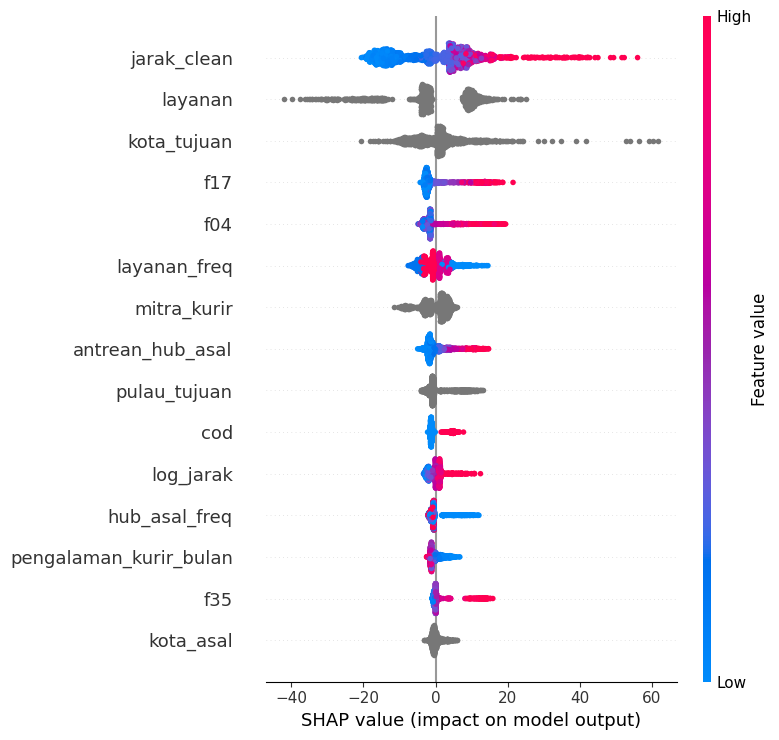


Melatih model final pada seluruh data latih (Jan-Agustus)...

=== TASK 1 SELESAI! ===
File prediksi_regresi.csv berhasil disimpan.
Total baris: 60000
Cek P90 >= P50: True
    id_paket    pred_p50    pred_p90
0  P83639399   60.149636   78.286056
1  P26553951  105.703309  134.464225
2  P32537117   58.694316   83.558076
3  P28750760   65.762063   86.717542
4  P96580009   54.146290   64.355834


In [15]:
import matplotlib.pyplot as plt

# --- 1f. ERROR BREAKDOWN BY LAYANAN, PULAU_TUJUAN, MITRA_KURIR ---
eval_analysis = va_fe.iloc[mid:].copy()
eval_analysis['pred_p50'] = p50_ev
eval_analysis['pred_p90_cal'] = p90_ev_calibrated
eval_analysis['pinball_p50'] = np.maximum(0.5 * (eval_analysis['durasi_jam'] - eval_analysis['pred_p50']),
                                          -0.5 * (eval_analysis['durasi_jam'] - eval_analysis['pred_p50']))
eval_analysis['pinball_p90'] = np.maximum(0.9 * (eval_analysis['durasi_jam'] - eval_analysis['pred_p90_cal']),
                                          -0.1 * (eval_analysis['durasi_jam'] - eval_analysis['pred_p90_cal']))
eval_analysis['covered_p90'] = (eval_analysis['durasi_jam'] <= eval_analysis['pred_p90_cal']).astype(int)

for col in ['layanan', 'pulau_tujuan', 'mitra_kurir']:
    print(f"\n=== 1f. ERROR BREAKDOWN BY {col.upper()} ===")
    summary = eval_analysis.groupby(col, observed=True).agg(
        jumlah_paket=('durasi_jam', 'count'),
        mean_actual_jam=('durasi_jam', 'mean'),
        pinball_p50=('pinball_p50', 'mean'),
        pinball_p90=('pinball_p90', 'mean'),
        p90_coverage=('covered_p90', 'mean')
    ).sort_values('pinball_p90', ascending=False)
    print(summary)

# --- 1f. INTERPRETASI MODEL (SHAP / FEATURE IMPORTANCE) ---
try:
    import shap
    explainer = shap.TreeExplainer(best_m50)
    sample_X = X_va.iloc[:1500]
    shap_values = explainer.shap_values(sample_X)
    plt.figure(figsize=(10, 5))
    shap.summary_plot(shap_values, sample_X, max_display=15, show=True)
except Exception as e:
    print("\n=== TOP 15 FEATURE IMPORTANCE (LIGHTGBM P50) ===")
    imp = pd.Series(best_m50.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
    print(imp)
    plt.figure(figsize=(8, 5))
    imp.sort_values().plot(kind='barh')
    plt.title("Top 15 Feature Importance (Model P50)")
    plt.xlabel("Importance (Split)")
    plt.tight_layout()
    plt.show()

# --- RETRAIN FULL DATA (JAN-AGU) & SIMPAN PREDIKSI_REGRESI.CSV ---
print("\nMelatih model final pada seluruh data latih (Jan-Agustus)...")
full_tr_fe, _, final_te_fe, final_features, _ = engineer_features_v2(train_df, val_raw, test_df)

X_full = full_tr_fe[final_features]
y_full = full_tr_fe['durasi_jam'].values
X_test = final_te_fe[final_features]

final_m50 = lgb.LGBMRegressor(objective='quantile', alpha=0.5, max_bin=63, subsample=0.8, colsample_bytree=0.8,
                              n_jobs=-1, random_state=42, verbose=-1, **best_params)
final_m90 = lgb.LGBMRegressor(objective='quantile', alpha=0.9, max_bin=63, subsample=0.8, colsample_bytree=0.8,
                              n_jobs=-1, random_state=42, verbose=-1, **best_params)

final_m50.fit(X_full, y_full)
final_m90.fit(X_full, y_full)

test_pred_p50 = np.maximum(final_m50.predict(X_test), 0.1)
test_pred_p90 = np.maximum(final_m90.predict(X_test) + conformal_offset, test_pred_p50)

submission_reg = pd.DataFrame({
    'id_paket': test_df['id_paket'],
    'pred_p50': test_pred_p50,
    'pred_p90': test_pred_p90
})

submission_reg.to_csv("prediksi_regresi.csv", index=False)
print("\n=== TASK 1 SELESAI! ===")
print("File prediksi_regresi.csv berhasil disimpan.")
print("Total baris:", len(submission_reg))
print("Cek P90 >= P50:", (submission_reg['pred_p90'] >= submission_reg['pred_p50']).all())
print(submission_reg.head())

In [ ]:

# ==========================================
# TASK 2: CLASSIFICATION - FRAUD DETECTION
# ==========================================

# Import library utama
import pandas as pd
import numpy as np

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Pengaturan
import warnings
warnings.filterwarnings("ignore")

SEED = 42

print("Semua library berhasil diimport!")


Semua library berhasil diimport!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving klasifikasi_train.csv.gz to klasifikasi_train.csv.gz
Saving klasifikasi_test.csv.gz to klasifikasi_test.csv.gz


In [ ]:

train = pd.read_csv("klasifikasi_train.csv.gz")
test = pd.read_csv("klasifikasi_test.csv.gz")

print("Dataset berhasil dibaca!")

print("Jumlah data training:", train.shape)
print("Jumlah data testing:", test.shape)


Dataset berhasil dibaca!
Jumlah data training: (403077, 85)
Jumlah data testing: (106674, 84)


In [ ]:

print("Lima data pertama:")
display(train.head())

print("\nInformasi kolom:")
display(train.info())

print("\nDaftar kolom:")
print(train.columns.tolist())


Lima data pertama:


,id_transaksi,waktu,id_pengguna,id_merchant,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,...,v42,v43,v44,v45,v46,v47,v48,v49,v50,is_fraud
0,T464739637,2025-07-19 19:30:41,U103280,M04468,kecantikan,qris,android,26600.0,19,0,...,0.350,0.814,-0.5,-1.018,1.378,0.232,0.142,-0.5,0.291,0
1,T555813708,2025-08-18 20:49:21,U127558,M02239,toko_online,aplikasi,android,179300.0,20,0,...,0.284,-0.464,1.5,-1.889,-1.051,0.434,-0.280,-0.5,-0.621,0
2,T998564616,2025-02-25 03:29:04,U100074,M01144,makanan_minuman,qris,android,58800.0,3,0,...,0.359,-0.172,1.5,0.252,-0.363,-1.452,0.260,1.5,-1.211,0
3,T221231710,2025-07-04 10:09:24,U108689,M01424,kesehatan,va,android,147400.0,10,0,...,0.876,-0.447,1.5,0.346,1.291,0.999,0.376,1.5,-2.059,0
4,T253111101,2025-08-28 23:09:19,U021647,M00684,elektronik,va,android,305400.0,23,0,...,0.030,1.016,1.5,-0.368,-0.268,-0.430,0.581,-0.5,-0.799,0



Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403077 entries, 0 to 403076
Data columns (total 85 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id_transaksi               403077 non-null  object 
 1   waktu                      403077 non-null  object 
 2   id_pengguna                403077 non-null  object 
 3   id_merchant                403077 non-null  object 
 4   kategori_merchant          403077 non-null  object 
 5   kanal                      403077 non-null  object 
 6   tipe_perangkat             403077 non-null  object 
 7   nominal                    403077 non-null  float64
 8   jam                        403077 non-null  int64  
 9   hari_libur                 403077 non-null  int64  
 10  umur_akun_hari             403077 non-null  int64  
 11  level_kyc                  403077 non-null  int64  
 12  umur_pengguna_tahun        403077 non-null  int64  
 13  email_domai

None


Daftar kolom:
['id_transaksi', 'waktu', 'id_pengguna', 'id_merchant', 'kategori_merchant', 'kanal', 'tipe_perangkat', 'nominal', 'jam', 'hari_libur', 'umur_akun_hari', 'level_kyc', 'umur_pengguna_tahun', 'email_domain', 'umur_perangkat_hari', 'perangkat_baru', 'jumlah_akun_per_perangkat', 'ganti_password_7h', 'gagal_login_24j', 'jarak_lokasi_km', 'negara_ip_beda', 'kartu_tidak_hadir', 'menit_sejak_trx_terakhir', 'trx_1j', 'trx_24j', 'trx_7h', 'nominal_24j', 'rasio_nominal_rata2', 'saldo_sebelum', 'persen_saldo', 'umur_merchant_hari', 'refund_merchant_30h', 'volume_merchant_30h', 'flag_review_manual', 'v01', 'v02', 'v03', 'v04', 'v05', 'v06', 'v07', 'v08', 'v09', 'v10', 'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20', 'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'v29', 'v30', 'v31', 'v32', 'v33', 'v34', 'v35', 'v36', 'v37', 'v38', 'v39', 'v40', 'v41', 'v42', 'v43', 'v44', 'v45', 'v46', 'v47', 'v48', 'v49', 'v50', 'is_fraud']


In [ ]:

# Membaca dataset training dan testing

train = pd.read_csv("klasifikasi_train.csv.gz")
test = pd.read_csv("klasifikasi_test.csv.gz")

print("Dataset berhasil dibaca!")

print("Jumlah data training:", train.shape)
print("Jumlah data testing:", test.shape)


Dataset berhasil dibaca!
Jumlah data training: (403077, 85)
Jumlah data testing: (106674, 84)


In [ ]:

print("Lima data pertama training:")
display(train.head())

print("Lima data pertama testing:")
display(test.head())


Lima data pertama training:


,id_transaksi,waktu,id_pengguna,id_merchant,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,...,v42,v43,v44,v45,v46,v47,v48,v49,v50,is_fraud
0,T464739637,2025-07-19 19:30:41,U103280,M04468,kecantikan,qris,android,26600.0,19,0,...,0.350,0.814,-0.5,-1.018,1.378,0.232,0.142,-0.5,0.291,0
1,T555813708,2025-08-18 20:49:21,U127558,M02239,toko_online,aplikasi,android,179300.0,20,0,...,0.284,-0.464,1.5,-1.889,-1.051,0.434,-0.280,-0.5,-0.621,0
2,T998564616,2025-02-25 03:29:04,U100074,M01144,makanan_minuman,qris,android,58800.0,3,0,...,0.359,-0.172,1.5,0.252,-0.363,-1.452,0.260,1.5,-1.211,0
3,T221231710,2025-07-04 10:09:24,U108689,M01424,kesehatan,va,android,147400.0,10,0,...,0.876,-0.447,1.5,0.346,1.291,0.999,0.376,1.5,-2.059,0
4,T253111101,2025-08-28 23:09:19,U021647,M00684,elektronik,va,android,305400.0,23,0,...,0.030,1.016,1.5,-0.368,-0.268,-0.430,0.581,-0.5,-0.799,0


Lima data pertama testing:


,id_transaksi,waktu,id_pengguna,id_merchant,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,...,v41,v42,v43,v44,v45,v46,v47,v48,v49,v50
0,T502861791,2025-09-28 03:34:59,U092684,M05338,hotel,aplikasi,ios,1494900.0,3,0,...,0.198,2.078,1.577,-0.5,-0.670,-0.501,1.385,1.943,-0.5,1.093
1,T980390558,2025-09-21 15:43:23,U051205,M06102,tagihan_listrik,aplikasi,android,48900.0,15,0,...,0.380,-1.577,-1.047,-0.5,1.009,0.375,-0.523,1.471,1.5,0.037
2,T657838379,2025-09-03 03:36:16,U079638,M07145,hotel,aplikasi,android,524100.0,3,0,...,0.233,0.655,2.714,1.5,1.546,0.392,-1.328,-8.948,1.5,0.397
3,T985886276,2025-10-13 21:10:41,U085269,M06849,rumah_tangga,va,android,535400.0,21,0,...,-1.326,-0.304,1.063,-0.5,1.672,0.485,1.604,1.146,1.5,0.808
4,T852019235,2025-10-30 06:49:39,U100942,M06729,tagihan_air,aplikasi,android,52500.0,6,0,...,0.929,0.627,-0.675,-0.5,-0.736,0.078,-0.799,-0.561,1.5,-0.416


In [ ]:

print("Informasi Dataset Training:")
train.info()

print("\nDaftar Kolom:")
print(train.columns.tolist())

print("\nJumlah Kolom Training:", len(train.columns))
print("Jumlah Kolom Testing:", len(test.columns))


Informasi Dataset Training:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403077 entries, 0 to 403076
Data columns (total 85 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id_transaksi               403077 non-null  object 
 1   waktu                      403077 non-null  object 
 2   id_pengguna                403077 non-null  object 
 3   id_merchant                403077 non-null  object 
 4   kategori_merchant          403077 non-null  object 
 5   kanal                      403077 non-null  object 
 6   tipe_perangkat             403077 non-null  object 
 7   nominal                    403077 non-null  float64
 8   jam                        403077 non-null  int64  
 9   hari_libur                 403077 non-null  int64  
 10  umur_akun_hari             403077 non-null  int64  
 11  level_kyc                  403077 non-null  int64  
 12  umur_pengguna_tahun        403077 non-null  int64  
 13  e

In [ ]:

print("Jumlah Missing Values:")
display(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nJumlah Data Duplikat:")
print(train.duplicated().sum())

print("\nDistribusi Label Fraud:")
display(train["is_fraud"].value_counts())

print("\nPersentase Label Fraud:")
display(train["is_fraud"].value_counts(normalize=True) * 100)


Jumlah Missing Values:


,0
menit_sejak_trx_terakhir,102621
rasio_nominal_rata2,102621
id_pengguna,0
waktu,0
id_transaksi,0
kanal,0
tipe_perangkat,0
nominal,0
jam,0
hari_libur,0



Jumlah Data Duplikat:
0

Distribusi Label Fraud:


,count
is_fraud,
0,400455
1,2622



Persentase Label Fraud:


,proportion
is_fraud,
0,99.349504
1,0.650496


In [ ]:
train = pd.read_csv("klasifikasi_train.csv.gz")
test = pd.read_csv("klasifikasi_test.csv.gz")

print("Train:", train.shape)
print("Test:", test.shape)

Train: (403077, 85)
Test: (106674, 84)


In [ ]:
display(train.head())
display(test.head())

,id_transaksi,waktu,id_pengguna,id_merchant,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,...,v42,v43,v44,v45,v46,v47,v48,v49,v50,is_fraud
0,T464739637,2025-07-19 19:30:41,U103280,M04468,kecantikan,qris,android,26600.0,19,0,...,0.350,0.814,-0.5,-1.018,1.378,0.232,0.142,-0.5,0.291,0
1,T555813708,2025-08-18 20:49:21,U127558,M02239,toko_online,aplikasi,android,179300.0,20,0,...,0.284,-0.464,1.5,-1.889,-1.051,0.434,-0.280,-0.5,-0.621,0
2,T998564616,2025-02-25 03:29:04,U100074,M01144,makanan_minuman,qris,android,58800.0,3,0,...,0.359,-0.172,1.5,0.252,-0.363,-1.452,0.260,1.5,-1.211,0
3,T221231710,2025-07-04 10:09:24,U108689,M01424,kesehatan,va,android,147400.0,10,0,...,0.876,-0.447,1.5,0.346,1.291,0.999,0.376,1.5,-2.059,0
4,T253111101,2025-08-28 23:09:19,U021647,M00684,elektronik,va,android,305400.0,23,0,...,0.030,1.016,1.5,-0.368,-0.268,-0.430,0.581,-0.5,-0.799,0


,id_transaksi,waktu,id_pengguna,id_merchant,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,...,v41,v42,v43,v44,v45,v46,v47,v48,v49,v50
0,T502861791,2025-09-28 03:34:59,U092684,M05338,hotel,aplikasi,ios,1494900.0,3,0,...,0.198,2.078,1.577,-0.5,-0.670,-0.501,1.385,1.943,-0.5,1.093
1,T980390558,2025-09-21 15:43:23,U051205,M06102,tagihan_listrik,aplikasi,android,48900.0,15,0,...,0.380,-1.577,-1.047,-0.5,1.009,0.375,-0.523,1.471,1.5,0.037
2,T657838379,2025-09-03 03:36:16,U079638,M07145,hotel,aplikasi,android,524100.0,3,0,...,0.233,0.655,2.714,1.5,1.546,0.392,-1.328,-8.948,1.5,0.397
3,T985886276,2025-10-13 21:10:41,U085269,M06849,rumah_tangga,va,android,535400.0,21,0,...,-1.326,-0.304,1.063,-0.5,1.672,0.485,1.604,1.146,1.5,0.808
4,T852019235,2025-10-30 06:49:39,U100942,M06729,tagihan_air,aplikasi,android,52500.0,6,0,...,0.929,0.627,-0.675,-0.5,-0.736,0.078,-0.799,-0.561,1.5,-0.416


In [ ]:
train.info()

print("\nKolom:")
print(train.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403077 entries, 0 to 403076
Data columns (total 85 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id_transaksi               403077 non-null  object 
 1   waktu                      403077 non-null  object 
 2   id_pengguna                403077 non-null  object 
 3   id_merchant                403077 non-null  object 
 4   kategori_merchant          403077 non-null  object 
 5   kanal                      403077 non-null  object 
 6   tipe_perangkat             403077 non-null  object 
 7   nominal                    403077 non-null  float64
 8   jam                        403077 non-null  int64  
 9   hari_libur                 403077 non-null  int64  
 10  umur_akun_hari             403077 non-null  int64  
 11  level_kyc                  403077 non-null  int64  
 12  umur_pengguna_tahun        403077 non-null  int64  
 13  email_domain               40

In [ ]:
print("Missing Values:")
display(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nDuplikasi:", train.duplicated().sum())

print("\nDistribusi Fraud:")
display(train["is_fraud"].value_counts())

print("\nPersentase Fraud:")
display(train["is_fraud"].value_counts(normalize=True) * 100)

Missing Values:


,0
menit_sejak_trx_terakhir,102621
rasio_nominal_rata2,102621
id_pengguna,0
waktu,0
id_transaksi,0
kanal,0
tipe_perangkat,0
nominal,0
jam,0
hari_libur,0



Duplikasi: 0

Distribusi Fraud:


,count
is_fraud,
0,400455
1,2622



Persentase Fraud:


,proportion
is_fraud,
0,99.349504
1,0.650496


In [ ]:

# ==========================================
# TASK 2A: LABEL AND FEATURE AUDIT
# ==========================================

# 1. Memeriksa waktu transaksi
train["waktu"] = pd.to_datetime(train["waktu"], errors="coerce")

print("Rentang waktu transaksi:")
print("Mulai :", train["waktu"].min())
print("Selesai:", train["waktu"].max())

print("\nJumlah waktu yang tidak valid:")
print(train["waktu"].isna().sum())


# 2. Distribusi fraud berdasarkan bulan
train["bulan"] = train["waktu"].dt.to_period("M")

fraud_per_bulan = train.groupby("bulan")["is_fraud"].agg(
    total_transaksi="count",
    jumlah_fraud="sum",
    persentase_fraud="mean"
)

fraud_per_bulan["persentase_fraud"] *= 100

display(fraud_per_bulan)


# 3. Memeriksa flag review manual
if "flag_review_manual" in train.columns:
    print("\nDistribusi Flag Review Manual:")
    display(pd.crosstab(
        train["flag_review_manual"],
        train["is_fraud"],
        margins=True
    ))

    print("\nTingkat fraud berdasarkan flag review:")
    display(
        train.groupby("flag_review_manual")["is_fraud"].mean() * 100
    )


Rentang waktu transaksi:
Mulai : 2025-01-01 00:02:53
Selesai: 2025-08-31 23:58:04

Jumlah waktu yang tidak valid:
0


,total_transaksi,jumlah_fraud,persentase_fraud
bulan,,,
2025-01,50432,327,0.648398
2025-02,46240,301,0.650952
2025-03,51048,387,0.758110
2025-04,47413,355,0.748740
2025-05,52331,367,0.701305
2025-06,50375,299,0.593548
2025-07,52334,341,0.651584
2025-08,52904,245,0.463103



Distribusi Flag Review Manual:


is_fraud,0,1,All
flag_review_manual,,,
0,395652,527,396179
1,4803,2095,6898
All,400455,2622,403077



Tingkat fraud berdasarkan flag review:


,is_fraud
flag_review_manual,
0,0.133021
1,30.371122


In [ ]:

# Memeriksa kolom yang perlu diaudit

print("Fitur yang perlu diperiksa:")

kolom_audit = [
    "flag_review_manual",
    "is_fraud",
    "waktu",
    "id_transaksi",
    "id_pengguna",
    "id_merchant",
    "v01", "v02", "v03", "v04", "v05"
]

for kolom in kolom_audit:
    if kolom in train.columns:
        print(
            kolom,
            "| dtype:", train[kolom].dtype,
            "| unique:", train[kolom].nunique(),
            "| missing:", train[kolom].isna().sum()
        )


Fitur yang perlu diperiksa:
flag_review_manual | dtype: int64 | unique: 2 | missing: 0
is_fraud | dtype: int64 | unique: 2 | missing: 0
waktu | dtype: datetime64[ns] | unique: 398219 | missing: 0
id_transaksi | dtype: object | unique: 403077 | missing: 0
id_pengguna | dtype: object | unique: 102621 | missing: 0
id_merchant | dtype: object | unique: 7914 | missing: 0
v01 | dtype: float64 | unique: 3401 | missing: 0
v02 | dtype: float64 | unique: 4586 | missing: 0
v03 | dtype: float64 | unique: 10761 | missing: 0
v04 | dtype: float64 | unique: 2 | missing: 0
v05 | dtype: float64 | unique: 6694 | missing: 0


In [ ]:

# ==========================================
# TASK 2A: MISSING VALUE ANALYSIS
# ==========================================

kolom_missing = [
    "menit_sejak_trx_terakhir",
    "rasio_nominal_rata2"
]

for kolom in kolom_missing:

    print("\nAnalisis:", kolom)

    train["status_missing"] = train[kolom].isna()

    hasil = train.groupby("status_missing").agg(
        jumlah_transaksi=("is_fraud", "count"),
        jumlah_fraud=("is_fraud", "sum"),
        persentase_fraud=("is_fraud", "mean")
    )

    hasil["persentase_fraud"] *= 100

    display(hasil)

train.drop(columns=["status_missing"], inplace=True)


Analisis: menit_sejak_trx_terakhir


,jumlah_transaksi,jumlah_fraud,persentase_fraud
status_missing,,,
False,300456,1662,0.553159
True,102621,960,0.935481



Analisis: rasio_nominal_rata2


,jumlah_transaksi,jumlah_fraud,persentase_fraud
status_missing,,,
False,300456,1662,0.553159
True,102621,960,0.935481


Rentang waktu transaksi:
Mulai: 2025-01-01 00:02:53
Selesai: 2025-08-31 23:58:04

Jumlah waktu tidak valid:
0


,total_transaksi,jumlah_fraud,persentase_fraud
bulan,,,
2025-01,50432,327,0.648398
2025-02,46240,301,0.650952
2025-03,51048,387,0.758110
2025-04,47413,355,0.748740
2025-05,52331,367,0.701305
2025-06,50375,299,0.593548
2025-07,52334,341,0.651584
2025-08,52904,245,0.463103


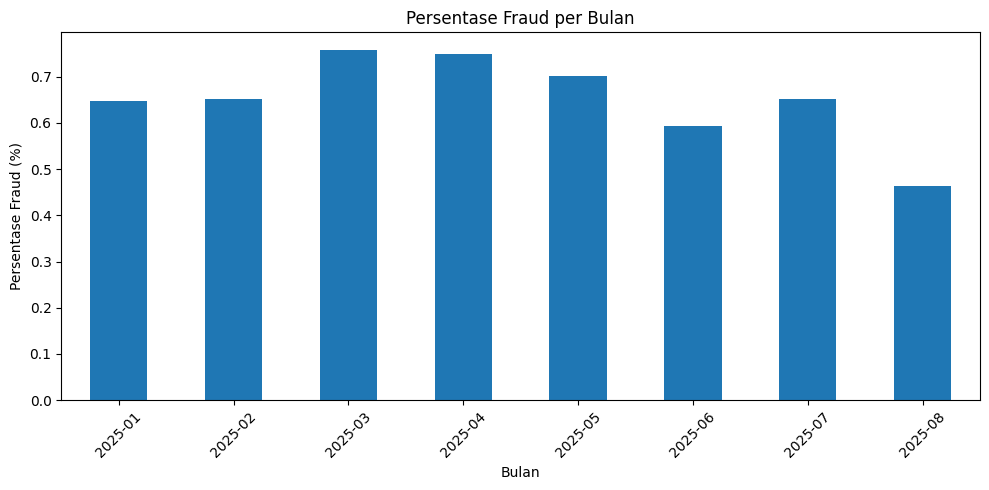

In [ ]:

# ==========================================
# TASK 2A: TIME AND LABEL AUDIT
# ==========================================

train["waktu"] = pd.to_datetime(
    train["waktu"],
    errors="coerce"
)

print("Rentang waktu transaksi:")
print("Mulai:", train["waktu"].min())
print("Selesai:", train["waktu"].max())

print("\nJumlah waktu tidak valid:")
print(train["waktu"].isna().sum())

# Distribusi fraud berdasarkan bulan
train["bulan"] = train["waktu"].dt.to_period("M")

fraud_per_bulan = train.groupby("bulan").agg(
    total_transaksi=("is_fraud", "count"),
    jumlah_fraud=("is_fraud", "sum"),
    persentase_fraud=("is_fraud", "mean")
)

fraud_per_bulan["persentase_fraud"] *= 100

display(fraud_per_bulan)

# Visualisasi
fraud_per_bulan["persentase_fraud"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Persentase Fraud per Bulan"
)

plt.ylabel("Persentase Fraud (%)")
plt.xlabel("Bulan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

# ==========================================
# AUDIT FLAG REVIEW MANUAL
# ==========================================

print("Distribusi Flag Review Manual:")

display(
    pd.crosstab(
        train["flag_review_manual"],
        train["is_fraud"],
        margins=True
    )
)

print("\nPersentase Fraud berdasarkan Review:")

display(
    train.groupby("flag_review_manual")["is_fraud"].mean() * 100
)

Distribusi Flag Review Manual:


is_fraud,0,1,All
flag_review_manual,,,
0,395652,527,396179
1,4803,2095,6898
All,400455,2622,403077



Persentase Fraud berdasarkan Review:


,is_fraud
flag_review_manual,
0,0.133021
1,30.371122


Rentang waktu transaksi:
Mulai: 2025-01-01 00:02:53
Selesai: 2025-08-31 23:58:04

Jumlah waktu tidak valid:
0


,total_transaksi,jumlah_fraud,persentase_fraud
bulan,,,
2025-01,50432,327,0.648398
2025-02,46240,301,0.650952
2025-03,51048,387,0.758110
2025-04,47413,355,0.748740
2025-05,52331,367,0.701305
2025-06,50375,299,0.593548
2025-07,52334,341,0.651584
2025-08,52904,245,0.463103


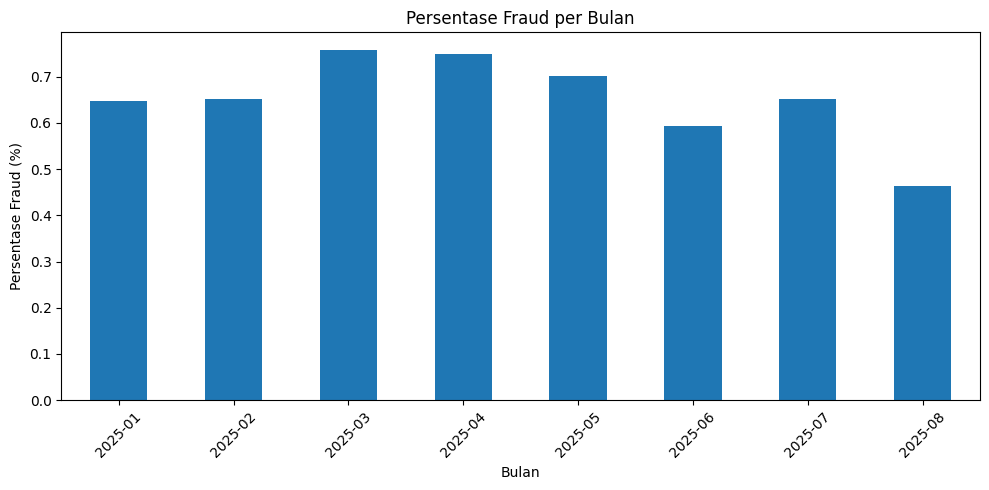

In [ ]:

# ==========================================
# TASK 2A: TIME AND LABEL AUDIT
# ==========================================

train["waktu"] = pd.to_datetime(
    train["waktu"],
    errors="coerce"
)

print("Rentang waktu transaksi:")
print("Mulai:", train["waktu"].min())
print("Selesai:", train["waktu"].max())

print("\nJumlah waktu tidak valid:")
print(train["waktu"].isna().sum())

# Analisis fraud berdasarkan bulan
train["bulan"] = train["waktu"].dt.to_period("M")

fraud_per_bulan = train.groupby("bulan").agg(
    total_transaksi=("is_fraud", "count"),
    jumlah_fraud=("is_fraud", "sum"),
    persentase_fraud=("is_fraud", "mean")
)

fraud_per_bulan["persentase_fraud"] *= 100

display(fraud_per_bulan)

# Visualisasi
fraud_per_bulan["persentase_fraud"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Persentase Fraud per Bulan"
)

plt.ylabel("Persentase Fraud (%)")
plt.xlabel("Bulan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# AUDIT FLAG REVIEW MANUAL
# ==========================================

print("Distribusi Flag Review Manual:")

display(pd.crosstab(
    train["flag_review_manual"],
    train["is_fraud"],
    margins=True
))

print("\nFraud Rate berdasarkan Flag Review:")

display(
    train.groupby("flag_review_manual")["is_fraud"].mean() * 100
)


Distribusi Flag Review Manual:


is_fraud,0,1,All
flag_review_manual,,,
0,395652,527,396179
1,4803,2095,6898
All,400455,2622,403077



Fraud Rate berdasarkan Flag Review:


,is_fraud
flag_review_manual,
0,0.133021
1,30.371122


In [ ]:

# ==========================================
# TASK 2B: TIME-BASED VALIDATION
# ==========================================

# Mengurutkan data berdasarkan waktu
train_sorted = train.sort_values(
    "waktu"
).reset_index(drop=True)

# Membagi data berdasarkan urutan waktu
split_index = int(len(train_sorted) * 0.80)

# 80% data awal untuk training
train_model = train_sorted.iloc[:split_index].copy()

# 20% data terakhir untuk validation
valid_model = train_sorted.iloc[split_index:].copy()

print("Jumlah data keseluruhan:", len(train_sorted))
print("Jumlah data training:", len(train_model))
print("Jumlah data validation:", len(valid_model))

print("\nRentang waktu training:")
print(train_model["waktu"].min(), "sampai", train_model["waktu"].max())

print("\nRentang waktu validation:")
print(valid_model["waktu"].min(), "sampai", valid_model["waktu"].max())

# Memastikan tidak ada tumpang tindih waktu
print("\nApakah urutan waktu valid?")
print(
    train_model["waktu"].max()
    <= valid_model["waktu"].min()
)


Jumlah data keseluruhan: 403077
Jumlah data training: 322461
Jumlah data validation: 80616

Rentang waktu training:
2025-01-01 00:02:53 sampai 2025-07-15 12:02:38

Rentang waktu validation:
2025-07-15 12:03:28 sampai 2025-08-31 23:58:04

Apakah urutan waktu valid?
True


In [ ]:

# Distribusi fraud pada training
print("DISTRIBUSI FRAUD TRAINING")

display(
    train_model["is_fraud"].value_counts()
)

print("\nPersentase fraud training:")

display(
    train_model["is_fraud"].value_counts(normalize=True) * 100
)


# Distribusi fraud pada validation
print("\nDISTRIBUSI FRAUD VALIDATION")

display(
    valid_model["is_fraud"].value_counts()
)

print("\nPersentase fraud validation:")

display(
    valid_model["is_fraud"].value_counts(normalize=True) * 100
)


DISTRIBUSI FRAUD TRAINING


,count
is_fraud,
0,320238
1,2223



Persentase fraud training:


,proportion
is_fraud,
0,99.310614
1,0.689386



DISTRIBUSI FRAUD VALIDATION


,count
is_fraud,
0,80217
1,399



Persentase fraud validation:


,proportion
is_fraud,
0,99.505061
1,0.494939


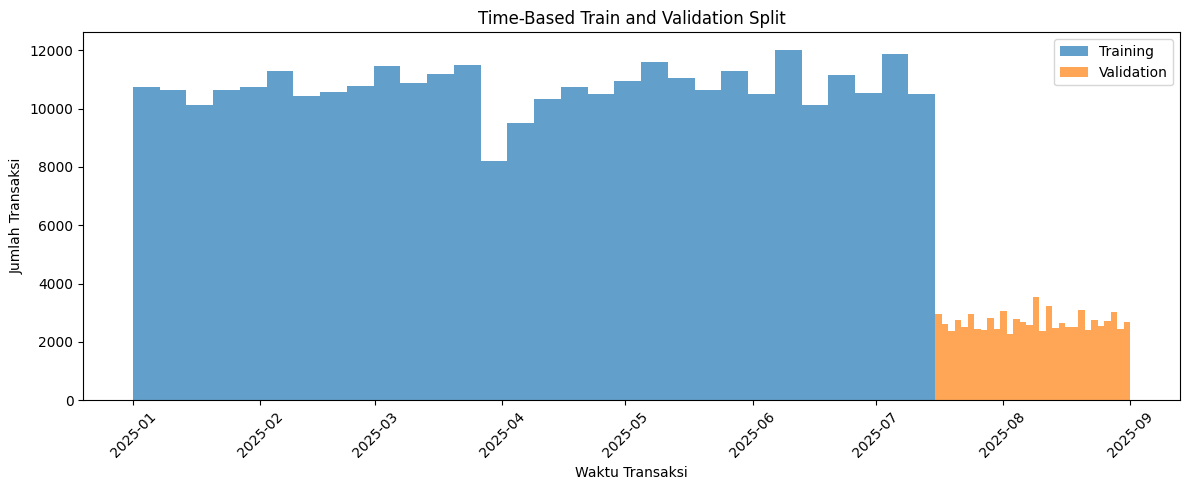

In [ ]:

# Visualisasi pembagian data berdasarkan waktu

plt.figure(figsize=(12, 5))

plt.hist(
    train_model["waktu"],
    bins=30,
    alpha=0.7,
    label="Training"
)

plt.hist(
    valid_model["waktu"],
    bins=30,
    alpha=0.7,
    label="Validation"
)

plt.title("Time-Based Train and Validation Split")
plt.xlabel("Waktu Transaksi")
plt.ylabel("Jumlah Transaksi")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# TASK 2C: BEHAVIORAL FEATURE ENGINEERING
# ==========================================

def create_behavioral_features(df):

    df = df.copy()

    # 1. Indikator missing value
    df["missing_riwayat_transaksi"] = (
        df["menit_sejak_trx_terakhir"].isna()
    ).astype(int)

    df["missing_rasio_nominal"] = (
        df["rasio_nominal_rata2"].isna()
    ).astype(int)

    # 2. Aktivitas transaksi pengguna
    df["rasio_trx_1j_24j"] = (
        df["trx_1j"] / (df["trx_24j"] + 1)
    )

    df["rata_nominal_per_trx"] = (
        df["nominal_24j"] / (df["trx_24j"] + 1)
    )

    # 3. Intensitas penggunaan saldo
    df["rasio_nominal_saldo"] = (
        df["nominal"] / (df["saldo_sebelum"] + 1)
    )

    # 4. Indikator transaksi bernilai tinggi
    df["transaksi_nominal_tinggi"] = (
        df["rasio_nominal_rata2"] > 3
    ).fillna(False).astype(int)

    # 5. Indikator perangkat berisiko
    df["perangkat_banyak_akun"] = (
        df["jumlah_akun_per_perangkat"] > 3
    ).astype(int)

    # 6. Indikator aktivitas login
    df["aktivitas_login_mencurigakan"] = (
        (df["gagal_login_24j"] > 3) |
        (df["ganti_password_7h"] > 0)
    ).astype(int)

    # 7. Indikator lokasi berisiko
    df["lokasi_berisiko"] = (
        (df["jarak_lokasi_km"] > 100) |
        (df["negara_ip_beda"] == 1)
    ).astype(int)

    return df


# Terapkan pada training dan validation
train_fe = create_behavioral_features(train_model)
valid_fe = create_behavioral_features(valid_model)

print("Feature engineering berhasil!")

print("Jumlah fitur awal:", train_model.shape[1])
print("Jumlah fitur setelah engineering:", train_fe.shape[1])

print("\nFitur tambahan:")
display(train_fe.columns.difference(train_model.columns).tolist())


Feature engineering berhasil!
Jumlah fitur awal: 86
Jumlah fitur setelah engineering: 95

Fitur tambahan:


['aktivitas_login_mencurigakan',
 'lokasi_berisiko',
 'missing_rasio_nominal',
 'missing_riwayat_transaksi',
 'perangkat_banyak_akun',
 'rasio_nominal_saldo',
 'rasio_trx_1j_24j',
 'rata_nominal_per_trx',
 'transaksi_nominal_tinggi']

In [ ]:

# Memeriksa fitur tambahan

fitur_baru = train_fe.columns.difference(
    train_model.columns
).tolist()

display(train_fe[fitur_baru].head())

print("\nMissing values setelah feature engineering:")
display(
    train_fe[fitur_baru].isnull().sum()
)


,aktivitas_login_mencurigakan,lokasi_berisiko,missing_rasio_nominal,missing_riwayat_transaksi,perangkat_banyak_akun,rasio_nominal_saldo,rasio_trx_1j_24j,rata_nominal_per_trx,transaksi_nominal_tinggi
0,0,0,1,1,0,0.382270,0.0,0.0,0
1,0,0,1,1,0,0.841387,0.0,0.0,0
2,0,0,1,1,0,0.264170,0.0,0.0,0
3,0,0,1,1,0,0.264491,0.0,0.0,0
4,0,0,1,1,0,0.211863,0.0,0.0,0



Missing values setelah feature engineering:


,0
aktivitas_login_mencurigakan,0
lokasi_berisiko,0
missing_rasio_nominal,0
missing_riwayat_transaksi,0
perangkat_banyak_akun,0
rasio_nominal_saldo,0
rasio_trx_1j_24j,0
rata_nominal_per_trx,0
transaksi_nominal_tinggi,0


In [ ]:

# ==========================================
# TASK 2C: FEATURE SANITY CHECK
# ==========================================

fitur_baru = [
    "missing_riwayat_transaksi",
    "missing_rasio_nominal",
    "rasio_trx_1j_24j",
    "rata_nominal_per_trx",
    "rasio_nominal_saldo",
    "transaksi_nominal_tinggi",
    "perangkat_banyak_akun",
    "aktivitas_login_mencurigakan",
    "lokasi_berisiko"
]

print("Jumlah nilai unik setiap fitur:")

display(train_fe[fitur_baru].nunique())

print("\nPemeriksaan nilai infinite:")

print(
    np.isinf(
        train_fe[fitur_baru].select_dtypes(
            include=np.number
        )
    ).sum()
)

print("\nStatistik fitur baru:")

display(train_fe[fitur_baru].describe().T)


Jumlah nilai unik setiap fitur:


,0
missing_riwayat_transaksi,2
missing_rasio_nominal,2
rasio_trx_1j_24j,19
rata_nominal_per_trx,5746
rasio_nominal_saldo,306776
transaksi_nominal_tinggi,2
perangkat_banyak_akun,2
aktivitas_login_mencurigakan,2
lokasi_berisiko,2



Pemeriksaan nilai infinite:
missing_riwayat_transaksi       0
missing_rasio_nominal           0
rasio_trx_1j_24j                0
rata_nominal_per_trx            0
rasio_nominal_saldo             0
transaksi_nominal_tinggi        0
perangkat_banyak_akun           0
aktivitas_login_mencurigakan    0
lokasi_berisiko                 0
dtype: int64

Statistik fitur baru:


,count,mean,std,min,25%,50%,75%,max
missing_riwayat_transaksi,322461.0,0.287275,0.452492,0.000000,0.000000,0.000000,1.000000,1.000000e+00
missing_rasio_nominal,322461.0,0.287275,0.452492,0.000000,0.000000,0.000000,1.000000,1.000000e+00
rasio_trx_1j_24j,322461.0,0.011921,0.086350,0.000000,0.000000,0.000000,0.000000,9.090909e-01
rata_nominal_per_trx,322461.0,5970.646298,57726.671397,0.000000,0.000000,0.000000,0.000000,5.048100e+06
rasio_nominal_saldo,322461.0,1.113698,4.249230,0.000339,0.133641,0.359375,0.983586,1.170219e+03
transaksi_nominal_tinggi,322461.0,0.107046,0.309172,0.000000,0.000000,0.000000,0.000000,1.000000e+00
perangkat_banyak_akun,322461.0,0.068169,0.252037,0.000000,0.000000,0.000000,0.000000,1.000000e+00
aktivitas_login_mencurigakan,322461.0,0.025693,0.158218,0.000000,0.000000,0.000000,0.000000,1.000000e+00
lokasi_berisiko,322461.0,0.039332,0.194384,0.000000,0.000000,0.000000,0.000000,1.000000e+00


In [ ]:

# ==========================================
# TASK 2D: PREPARE MODELING DATA
# ==========================================

# Target
y_train = train_fe["is_fraud"]
y_valid = valid_fe["is_fraud"]

# Kolom yang tidak digunakan sebagai fitur
drop_cols = [
    "is_fraud",
    "id_transaksi",
    "id_pengguna",
    "id_merchant",
    "waktu",
    "bulan",
    "flag_review_manual"
]

X_train = train_fe.drop(
    columns=drop_cols,
    errors="ignore"
)

X_valid = valid_fe.drop(
    columns=drop_cols,
    errors="ignore"
)

# Identifikasi fitur kategorikal dan numerik
cat_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

num_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Jumlah fitur:", X_train.shape[1])
print("Fitur numerik:", len(num_cols))
print("Fitur kategorikal:", len(cat_cols))

print("\nJumlah data training:", X_train.shape)
print("Jumlah data validation:", X_valid.shape)

print("\nDistribusi target training:")
print(y_train.value_counts())


Jumlah fitur: 88
Fitur numerik: 84
Fitur kategorikal: 4

Jumlah data training: (322461, 88)
Jumlah data validation: (80616, 88)

Distribusi target training:
is_fraud
0    320238
1      2223
Name: count, dtype: int64


In [ ]:

# ==========================================
# TASK 2D: BASELINE LIGHTGBM
# ==========================================

from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Menyamakan kategori training dan validation
for col in cat_cols:
    categories = pd.Index(
        pd.concat([
            X_train[col].astype(str),
            X_valid[col].astype(str)
        ]).unique()
    )

    X_train[col] = pd.Categorical(
        X_train[col].astype(str),
        categories=categories
    )

    X_valid[col] = pd.Categorical(
        X_valid[col].astype(str),
        categories=categories
    )

# Membuat model baseline
model_baseline = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Training model
model_baseline.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="binary_logloss",
    callbacks=[
        early_stopping(50),
        log_evaluation(100)
    ]
)

print("Baseline LightGBM berhasil dilatih!")
print("Best iteration:", model_baseline.best_iteration_)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[41]	valid_0's binary_logloss: 0.0216493
Baseline LightGBM berhasil dilatih!
Best iteration: 41


In [ ]:

# ==========================================
# EVALUASI BASELINE LIGHTGBM
# ==========================================

# Prediksi probabilitas fraud
y_pred_proba = model_baseline.predict_proba(
    X_valid
)[:, 1]

# Threshold awal
threshold = 0.5

y_pred = (
    y_pred_proba >= threshold
).astype(int)

# Evaluasi
pr_auc = average_precision_score(
    y_valid,
    y_pred_proba
)

roc_auc = roc_auc_score(
    y_valid,
    y_pred_proba
)

print("=== HASIL EVALUASI BASELINE ===")
print("PR-AUC:", round(pr_auc, 5))
print("ROC-AUC:", round(roc_auc, 5))

print("\nClassification Report:")
print(
    classification_report(
        y_valid,
        y_pred,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(y_valid, y_pred),
        index=["Aktual Normal", "Aktual Fraud"],
        columns=["Prediksi Normal", "Prediksi Fraud"]
    )
)


=== HASIL EVALUASI BASELINE ===
PR-AUC: 0.3714
ROC-AUC: 0.90039

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     80217
           1       0.53      0.46      0.49       399

    accuracy                           1.00     80616
   macro avg       0.76      0.73      0.75     80616
weighted avg       1.00      1.00      1.00     80616


Confusion Matrix:


,Prediksi Normal,Prediksi Fraud
Aktual Normal,80053,164
Aktual Fraud,215,184


In [ ]:

# ==========================================
# EVALUASI BASELINE LIGHTGBM
# ==========================================

# Prediksi probabilitas fraud
y_pred_proba = model_baseline.predict_proba(
    X_valid
)[:, 1]

# Threshold awal
threshold = 0.5

y_pred = (
    y_pred_proba >= threshold
).astype(int)

# Evaluasi
pr_auc = average_precision_score(
    y_valid,
    y_pred_proba
)

roc_auc = roc_auc_score(
    y_valid,
    y_pred_proba
)

print("=== HASIL EVALUASI BASELINE ===")
print("PR-AUC:", round(pr_auc, 5))
print("ROC-AUC:", round(roc_auc, 5))

print("\nClassification Report:")
print(
    classification_report(
        y_valid,
        y_pred,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
display(
    pd.DataFrame(
        confusion_matrix(y_valid, y_pred),
        index=["Aktual Normal", "Aktual Fraud"],
        columns=["Prediksi Normal", "Prediksi Fraud"]
    )
)


=== HASIL EVALUASI BASELINE ===
PR-AUC: 0.3714
ROC-AUC: 0.90039

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     80217
           1       0.53      0.46      0.49       399

    accuracy                           1.00     80616
   macro avg       0.76      0.73      0.75     80616
weighted avg       1.00      1.00      1.00     80616


Confusion Matrix:


,Prediksi Normal,Prediksi Fraud
Aktual Normal,80053,164
Aktual Fraud,215,184


In [ ]:

# ==========================================
# MODEL 2: LIGHTGBM CLASS WEIGHT
# ==========================================

# Menghitung rasio class weight
scale_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("Scale Positive Weight:", scale_weight)

# Membuat model
model_weight = LGBMClassifier(
    objective="binary",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Training
model_weight.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="binary_logloss",
    callbacks=[
        early_stopping(50),
        log_evaluation(100)
    ]
)

print("Model Class Weight berhasil dilatih!")
print("Best iteration:", model_weight.best_iteration_)


Scale Positive Weight: 144.05668016194332
Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0946636
[200]	valid_0's binary_logloss: 0.0608605
[300]	valid_0's binary_logloss: 0.0470387
[400]	valid_0's binary_logloss: 0.0403722
[500]	valid_0's binary_logloss: 0.0363229
[600]	valid_0's binary_logloss: 0.034224
[700]	valid_0's binary_logloss: 0.0335047
[800]	valid_0's binary_logloss: 0.0331754
Early stopping, best iteration is:
[807]	valid_0's binary_logloss: 0.0331492
Model Class Weight berhasil dilatih!
Best iteration: 807


In [ ]:

# ==========================================
# EVALUASI MODEL 2
# ==========================================

y_weight_proba = model_weight.predict_proba(
    X_valid
)[:, 1]

y_weight_pred = (
    y_weight_proba >= 0.5
).astype(int)

pr_auc_weight = average_precision_score(
    y_valid,
    y_weight_proba
)

roc_auc_weight = roc_auc_score(
    y_valid,
    y_weight_proba
)

print("=== HASIL CLASS WEIGHT ===")
print("PR-AUC:", round(pr_auc_weight, 5))
print("ROC-AUC:", round(roc_auc_weight, 5))

print("\nClassification Report:")
print(classification_report(
    y_valid,
    y_weight_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_valid, y_weight_pred),
    index=["Aktual Normal", "Aktual Fraud"],
    columns=["Prediksi Normal", "Prediksi Fraud"]
))


=== HASIL CLASS WEIGHT ===
PR-AUC: 0.41078
ROC-AUC: 0.91413

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     80217
           1       0.51      0.60      0.55       399

    accuracy                           1.00     80616
   macro avg       0.75      0.80      0.77     80616
weighted avg       1.00      1.00      1.00     80616


Confusion Matrix:


,Prediksi Normal,Prediksi Fraud
Aktual Normal,79986,231
Aktual Fraud,160,239


In [ ]:

# ==========================================
# PERBANDINGAN MODEL 1 DAN MODEL 2
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Baseline LightGBM",
        "LightGBM Class Weight"
    ],
    "PR-AUC": [
        pr_auc,
        pr_auc_weight
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_weight
    ]
})

display(comparison.sort_values(
    by="PR-AUC",
    ascending=False
))


,Model,PR-AUC,ROC-AUC
1,LightGBM Class Weight,0.410784,0.914131
0,Baseline LightGBM,0.371398,0.900386


In [ ]:

# ==========================================
# MODEL 3: THRESHOLD OPTIMIZATION
# ==========================================

from sklearn.metrics import (
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score
)

# Menghitung Precision dan Recall
precision, recall, thresholds = precision_recall_curve(
    y_valid,
    y_weight_proba
)

# Menghitung F1 Score untuk setiap threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

# Mencari threshold dengan F1 Score tertinggi
best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("=== HASIL THRESHOLD OPTIMIZATION ===")
print("Best Threshold:", round(best_threshold, 5))
print("Best F1 Score:", round(f1_scores[best_index], 5))
print("Precision:", round(precision[best_index], 5))
print("Recall:", round(recall[best_index], 5))


=== HASIL THRESHOLD OPTIMIZATION ===
Best Threshold: 0.91691
Best F1 Score: 0.57702
Precision: 0.60218
Recall: 0.55388


In [ ]:

# ==========================================
# EVALUASI MODEL DENGAN BEST THRESHOLD
# ==========================================

# Prediksi menggunakan threshold terbaik
y_weight_optimized = (
    y_weight_proba >= best_threshold
).astype(int)

print("=== HASIL EVALUASI THRESHOLD OPTIMIZATION ===")

print("Threshold:", round(best_threshold, 5))

print("\nClassification Report:")

print(classification_report(
    y_valid,
    y_weight_optimized,
    zero_division=0
))

print("\nConfusion Matrix:")

display(pd.DataFrame(
    confusion_matrix(y_valid, y_weight_optimized),
    index=["Aktual Normal", "Aktual Fraud"],
    columns=["Prediksi Normal", "Prediksi Fraud"]
))

print("\nPrecision:",
      round(precision_score(y_valid, y_weight_optimized), 5))

print("Recall:",
      round(recall_score(y_valid, y_weight_optimized), 5))

print("F1 Score:",
      round(f1_score(y_valid, y_weight_optimized), 5))


=== HASIL EVALUASI THRESHOLD OPTIMIZATION ===
Threshold: 0.91691

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     80217
           1       0.60      0.55      0.58       399

    accuracy                           1.00     80616
   macro avg       0.80      0.78      0.79     80616
weighted avg       1.00      1.00      1.00     80616


Confusion Matrix:


,Prediksi Normal,Prediksi Fraud
Aktual Normal,80071,146
Aktual Fraud,178,221



Precision: 0.60218
Recall: 0.55388
F1 Score: 0.57702


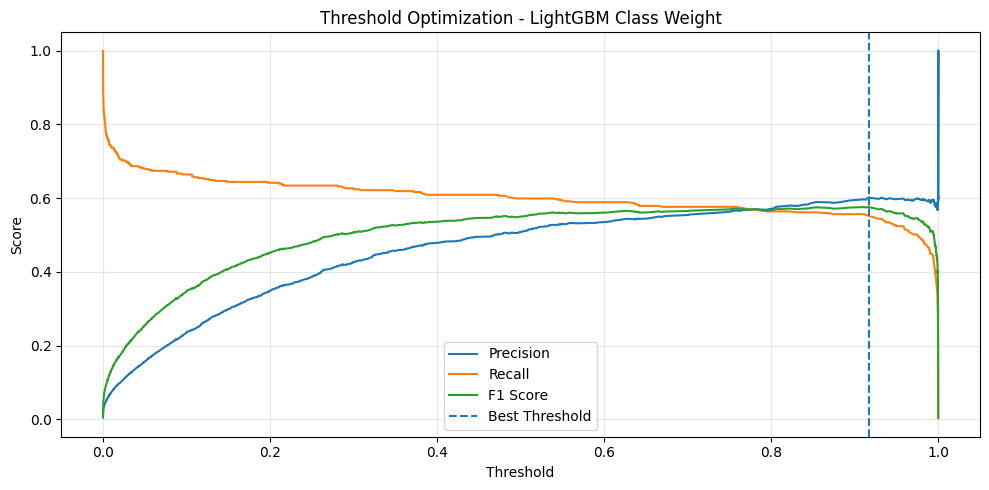

In [ ]:

# ==========================================
# VISUALISASI PRECISION, RECALL, DAN F1
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1 Score")

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Best Threshold"
)

plt.title("Threshold Optimization - LightGBM Class Weight")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# FEATURE IMPORTANCE - MODEL CLASS WEIGHT
# ==========================================

# Mengambil feature importance berdasarkan gain
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_weight.booster_.feature_importance(
        importance_type="gain"
    )
})

# Mengurutkan fitur dari yang paling berpengaruh
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("=== TOP 20 FEATURE IMPORTANCE ===")
display(importance.head(20))


=== TOP 20 FEATURE IMPORTANCE ===


,Feature,Importance
18,menit_sejak_trx_terakhir,5.467628e+06
3,nominal,2.776947e+06
0,kategori_merchant,1.885578e+06
81,rasio_trx_1j_24j,1.792380e+06
86,aktivitas_login_mencurigakan,1.688732e+06
11,perangkat_baru,1.275213e+06
28,volume_merchant_30h,6.055545e+05
26,umur_merchant_hari,4.757750e+05
15,jarak_lokasi_km,3.278726e+05
12,jumlah_akun_per_perangkat,3.076615e+05


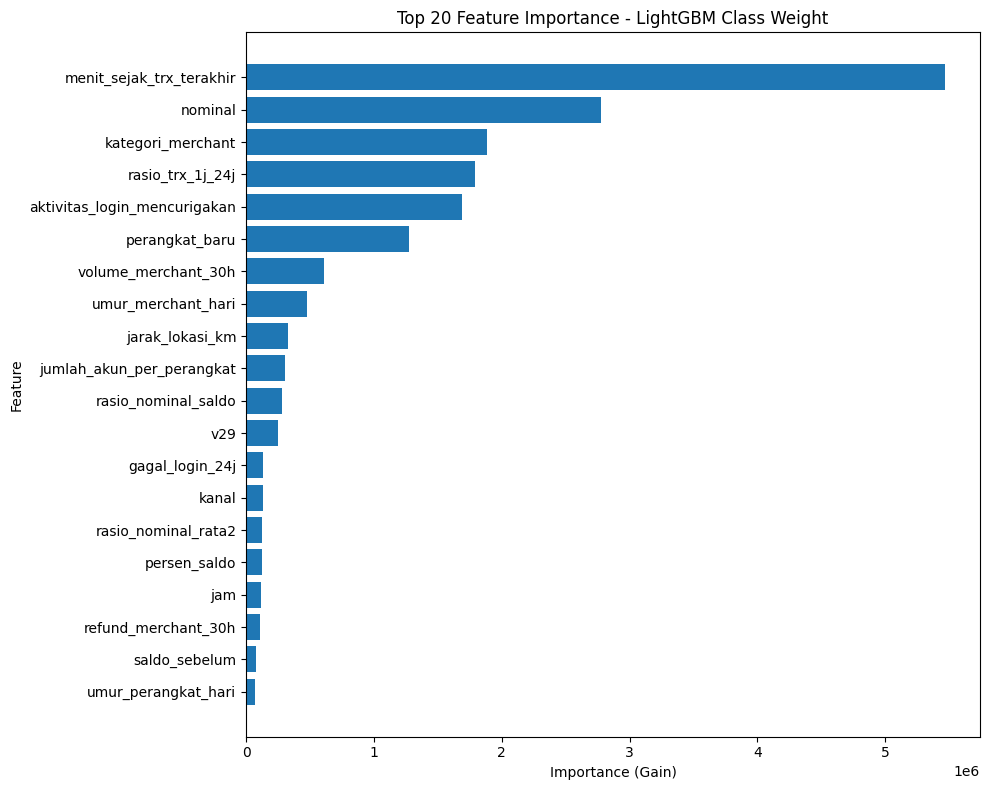

In [ ]:

# ==========================================
# VISUALISASI FEATURE IMPORTANCE
# ==========================================

top_features = importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 20 Feature Importance - LightGBM Class Weight")
plt.xlabel("Importance (Gain)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# ERROR ANALYSIS - FRAUD DETECTION
# ==========================================

error_analysis = X_valid.copy().reset_index(drop=True)

error_analysis["actual"] = np.asarray(y_valid)
error_analysis["predicted"] = np.asarray(y_weight_optimized)
error_analysis["fraud_probability"] = np.asarray(y_weight_proba)

# Mengelompokkan hasil prediksi
error_analysis["prediction_result"] = np.select(
    [
        (error_analysis["actual"] == 1) &
        (error_analysis["predicted"] == 1),

        (error_analysis["actual"] == 0) &
        (error_analysis["predicted"] == 0),

        (error_analysis["actual"] == 0) &
        (error_analysis["predicted"] == 1),

        (error_analysis["actual"] == 1) &
        (error_analysis["predicted"] == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

print("=== JUMLAH HASIL PREDIKSI ===")

display(
    error_analysis["prediction_result"]
    .value_counts()
    .to_frame("Jumlah")
)


=== JUMLAH HASIL PREDIKSI ===


,Jumlah
prediction_result,
True Negative,80071
True Positive,221
False Negative,178
False Positive,146


In [ ]:

# ==========================================
# ANALISIS FALSE NEGATIVE
# ==========================================

false_negative = error_analysis[
    error_analysis["prediction_result"] == "False Negative"
]

print("Jumlah False Negative:", len(false_negative))

print("\nContoh transaksi fraud yang tidak terdeteksi:")

display(
    false_negative.sort_values(
        by="fraud_probability",
        ascending=False
    ).head(10)
)


Jumlah False Negative: 178

Contoh transaksi fraud yang tidak terdeteksi:


,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,umur_akun_hari,level_kyc,umur_pengguna_tahun,email_domain,...,rata_nominal_per_trx,rasio_nominal_saldo,transaksi_nominal_tinggi,perangkat_banyak_akun,aktivitas_login_mencurigakan,lokasi_berisiko,actual,predicted,fraud_probability,prediction_result
1053,elektronik,va,android,9755000.0,22,0,328,1,21,gmail,...,0.0,19.908123,0,0,0,0,1,0,0.911296,False Negative
48801,gadget,va,ios,369400.0,23,0,789,2,47,yahoo,...,0.0,0.355534,0,0,0,1,1,0,0.870230,False Negative
427,elektronik,qris,android,201800.0,16,0,1563,2,47,korporat,...,0.0,1.230480,1,0,0,0,1,0,0.853668,False Negative
34461,gadget,web,android,1441200.0,6,0,72,1,48,gmail,...,0.0,0.850628,1,0,0,1,1,0,0.821040,False Negative
22039,elektronik,web,android,360600.0,17,0,551,2,35,gmail,...,0.0,0.721353,0,0,0,0,1,0,0.786284,False Negative
32341,top_up_ewallet,aplikasi,android,1461900.0,20,0,967,0,44,gmail,...,0.0,0.847705,1,0,1,0,1,0,0.781301,False Negative
5432,fashion,aplikasi,android,260500.0,14,0,865,1,33,gmail,...,0.0,6.512337,0,0,0,0,1,0,0.771718,False Negative
3145,top_up_ewallet,aplikasi,ios,879300.0,7,0,1841,1,28,korporat,...,0.0,0.200845,1,0,1,1,1,0,0.765154,False Negative
60674,fashion,web,android,467500.0,7,0,1958,1,23,gmail,...,94450.0,0.752465,0,0,0,0,1,0,0.757996,False Negative
17984,gadget,aplikasi,android,164000.0,7,0,1684,1,20,gmail,...,333850.0,0.309433,0,0,0,1,1,0,0.665949,False Negative


In [ ]:

# ==========================================
# ANALISIS FALSE POSITIVE
# ==========================================

false_positive = error_analysis[
    error_analysis["prediction_result"] == "False Positive"
]

print("Jumlah False Positive:", len(false_positive))

print("\nContoh transaksi normal yang salah ditandai fraud:")

display(
    false_positive.sort_values(
        by="fraud_probability",
        ascending=False
    ).head(10)
)


Jumlah False Positive: 146

Contoh transaksi normal yang salah ditandai fraud:


,kategori_merchant,kanal,tipe_perangkat,nominal,jam,hari_libur,umur_akun_hari,level_kyc,umur_pengguna_tahun,email_domain,...,rata_nominal_per_trx,rasio_nominal_saldo,transaksi_nominal_tinggi,perangkat_banyak_akun,aktivitas_login_mencurigakan,lokasi_berisiko,actual,predicted,fraud_probability,prediction_result
37760,voucher_game,aplikasi,ios,152400.0,3,0,1294,0,50,gmail,...,60600.000000,0.773600,1,0,1,1,0,1,1.000000,False Positive
63011,toko_online,web,android,8000.0,14,0,4,0,26,gmail,...,8142.857143,0.004294,0,1,0,0,0,1,1.000000,False Positive
62994,toko_online,kartu,android,11000.0,14,0,4,0,26,gmail,...,7500.000000,0.012615,0,1,0,0,0,1,1.000000,False Positive
80383,pulsa_data,kartu,android,24000.0,20,0,1,0,17,gmail,...,25250.000000,0.016032,0,1,0,0,0,1,1.000000,False Positive
77558,pulsa_data,aplikasi,android,1116200.0,0,0,209,2,43,gmail,...,237300.000000,0.765993,1,0,1,0,0,1,1.000000,False Positive
62992,toko_online,kartu,android,6000.0,14,0,4,0,26,gmail,...,8000.000000,0.012500,0,1,0,0,0,1,1.000000,False Positive
49358,toko_online,kartu,android,34000.0,11,0,1,0,17,gmail,...,2333.333333,0.050296,1,0,0,0,0,1,1.000000,False Positive
77468,pulsa_data,aplikasi,web,26000.0,22,0,2,0,37,sekali_pakai,...,21200.000000,0.962927,0,1,0,1,0,1,1.000000,False Positive
80391,toko_online,kartu,ios,45000.0,20,0,1,0,17,gmail,...,28666.666667,0.014080,0,1,0,0,0,1,0.999999,False Positive
18843,toko_online,kartu,android,161400.0,16,0,2,0,25,sekali_pakai,...,20000.000000,0.604492,1,0,0,0,0,1,0.999999,False Positive


In [ ]:

# ==========================================
# PERBANDINGAN KARAKTERISTIK ERROR
# ==========================================

selected_features = [
    "nominal",
    "umur_akun_hari",
    "level_kyc",
    "rasio_nominal_saldo",
    "transaksi_nominal_tinggi",
    "perangkat_banyak_akun",
    "aktivitas_login_mencurigakan",
    "lokasi_berisiko",
    "fraud_probability"
]

available_features = [
    col for col in selected_features
    if col in error_analysis.columns
]

error_summary = error_analysis.groupby(
    "prediction_result"
)[available_features].mean()

print("=== RATA-RATA KARAKTERISTIK SETIAP KATEGORI ===")

display(error_summary.T)


=== RATA-RATA KARAKTERISTIK SETIAP KATEGORI ===


prediction_result,False Negative,False Positive,True Negative,True Positive
nominal,973771.348315,2.079212e+06,294773.195039,1.109876e+06
umur_akun_hari,1076.522472,3.700959e+02,877.140625,7.107783e+02
level_kyc,1.129213,8.493151e-01,1.046534,9.004525e-01
rasio_nominal_saldo,4.480583,2.388809e+01,1.057359,7.029804e+00
transaksi_nominal_tinggi,0.348315,8.904110e-02,0.110015,1.719457e-01
perangkat_banyak_akun,0.000000,2.054795e-01,0.068127,9.049774e-02
aktivitas_login_mencurigakan,0.067416,1.575342e-01,0.024491,4.072398e-01
lokasi_berisiko,0.106742,1.438356e-01,0.038179,3.122172e-01
fraud_probability,0.117779,9.943339e-01,0.003818,9.924876e-01


In [ ]:

# ==========================================
# ANALISIS KATEGORI MERCHANT
# ==========================================

for category in [
    "False Positive",
    "False Negative",
    "True Positive",
    "True Negative"
]:

    subset = error_analysis[
        error_analysis["prediction_result"] == category
    ]

    print(f"\n=== {category} ===")

    display(
        subset["kategori_merchant"]
        .value_counts()
        .head(10)
        .to_frame("Jumlah")
    )



=== False Positive ===


,Jumlah
kategori_merchant,
voucher_game,33
toko_online,26
pulsa_data,26
gadget,20
elektronik,15
emas,13
top_up_ewallet,10
makanan_minuman,1
hobi,1



=== False Negative ===


,Jumlah
kategori_merchant,
jasa_lainnya,40
toko_online,36
elektronik,17
kecantikan,13
fashion,12
gadget,11
top_up_ewallet,10
makanan_minuman,9
voucher_game,7



=== True Positive ===


,Jumlah
kategori_merchant,
voucher_game,38
elektronik,32
top_up_ewallet,28
gadget,26
pulsa_data,24
toko_online,23
emas,19
makanan_minuman,12
tagihan_listrik,4



=== True Negative ===


,Jumlah
kategori_merchant,
makanan_minuman,11794
elektronik,8485
pulsa_data,7757
toko_online,6331
fashion,5439
top_up_ewallet,4104
voucher_game,3576
kecantikan,3409
gadget,3262


In [ ]:

# ==========================================
# ANALISIS ERROR BERDASARKAN MERCHANT
# ==========================================

merchant_analysis = error_analysis.groupby(
    "kategori_merchant"
).agg(
    total_transaksi=("actual", "count"),
    total_fraud=("actual", "sum"),
    false_positive=("prediction_result",
                    lambda x: (x == "False Positive").sum()),
    false_negative=("prediction_result",
                    lambda x: (x == "False Negative").sum()),
    true_positive=("prediction_result",
                   lambda x: (x == "True Positive").sum())
)

merchant_analysis["fraud_rate"] = (
    merchant_analysis["total_fraud"] /
    merchant_analysis["total_transaksi"]
)

merchant_analysis["fraud_recall"] = (
    merchant_analysis["true_positive"] /
    merchant_analysis["total_fraud"].replace(0, np.nan)
)

merchant_analysis["error_rate"] = (
    (merchant_analysis["false_positive"] +
     merchant_analysis["false_negative"]) /
    merchant_analysis["total_transaksi"]
)

print("=== MERCHANT DENGAN FALSE NEGATIVE TERBANYAK ===")

display(
    merchant_analysis.sort_values(
        "false_negative",
        ascending=False
    ).head(15)
)


=== MERCHANT DENGAN FALSE NEGATIVE TERBANYAK ===


,total_transaksi,total_fraud,false_positive,false_negative,true_positive,fraud_rate,fraud_recall,error_rate
kategori_merchant,,,,,,,,
jasa_lainnya,1888,41,0,40,1,0.021716,0.024390,0.021186
toko_online,6416,59,26,36,23,0.009196,0.389831,0.009663
elektronik,8549,49,15,17,32,0.005732,0.653061,0.003743
kecantikan,3423,14,0,13,1,0.004090,0.071429,0.003798
fashion,5453,14,0,12,2,0.002567,0.142857,0.002201
gadget,3319,37,20,11,26,0.011148,0.702703,0.009340
top_up_ewallet,4152,38,10,10,28,0.009152,0.736842,0.004817
makanan_minuman,11816,21,1,9,12,0.001777,0.571429,0.000846
voucher_game,3654,45,33,7,38,0.012315,0.844444,0.010947


In [ ]:

# ==========================================
# ANALISIS KARAKTERISTIK FALSE NEGATIVE
# ==========================================

print("Jumlah transaksi False Negative:", len(false_negative))

# Distribusi False Negative berdasarkan merchant
print("\n=== DISTRIBUSI FALSE NEGATIVE ===")
display(
    false_negative["kategori_merchant"]
    .value_counts()
    .to_frame("jumlah_false_negative")
)

# Statistik fitur numerik
print("\n=== STATISTIK FITUR NUMERIK FALSE NEGATIVE ===")

numeric_fn = false_negative.select_dtypes(include="number")

display(numeric_fn.describe().T)


Jumlah transaksi False Negative: 178

=== DISTRIBUSI FALSE NEGATIVE ===


,jumlah_false_negative
kategori_merchant,
jasa_lainnya,40
toko_online,36
elektronik,17
kecantikan,13
fashion,12
gadget,11
top_up_ewallet,10
makanan_minuman,9
voucher_game,7



=== STATISTIK FITUR NUMERIK FALSE NEGATIVE ===


,count,mean,std,min,25%,50%,75%,max
nominal,178.0,973771.348315,1.005829e+06,9.000000e+03,221550.000000,707250.000000,1.500000e+06,9.755000e+06
jam,178.0,12.331461,4.825453e+00,0.000000e+00,10.000000,13.000000,1.500000e+01,2.300000e+01
hari_libur,178.0,0.022472,1.486305e-01,0.000000e+00,0.000000,0.000000,0.000000e+00,1.000000e+00
umur_akun_hari,178.0,1076.522472,5.671925e+02,4.600000e+01,618.000000,1038.000000,1.582750e+03,2.007000e+03
level_kyc,178.0,1.129213,7.131853e-01,0.000000e+00,1.000000,1.000000,2.000000e+00,2.000000e+00
...,...,...,...,...,...,...,...,...
aktivitas_login_mencurigakan,178.0,0.067416,2.514479e-01,0.000000e+00,0.000000,0.000000,0.000000e+00,1.000000e+00
lokasi_berisiko,178.0,0.106742,3.096555e-01,0.000000e+00,0.000000,0.000000,0.000000e+00,1.000000e+00
actual,178.0,1.000000,0.000000e+00,1.000000e+00,1.000000,1.000000,1.000000e+00,1.000000e+00
predicted,178.0,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00


In [ ]:

# ==========================================
# ANALISIS KARAKTERISTIK FALSE POSITIVE
# ==========================================

print("Jumlah transaksi False Positive:", len(false_positive))

print("\n=== DISTRIBUSI FALSE POSITIVE ===")

display(
    false_positive["kategori_merchant"]
    .value_counts()
    .to_frame("jumlah_false_positive")
)

print("\n=== STATISTIK FITUR NUMERIK FALSE POSITIVE ===")

numeric_fp = false_positive.select_dtypes(include="number")

display(numeric_fp.describe().T)


Jumlah transaksi False Positive: 146

=== DISTRIBUSI FALSE POSITIVE ===


,jumlah_false_positive
kategori_merchant,
voucher_game,33
toko_online,26
pulsa_data,26
gadget,20
elektronik,15
emas,13
top_up_ewallet,10
makanan_minuman,1
hobi,1



=== STATISTIK FITUR NUMERIK FALSE POSITIVE ===


,count,mean,std,min,25%,50%,75%,max
nominal,146.0,2.079212e+06,2.980249e+06,4000.000000,30000.000000,254900.00000,4.556425e+06,9937300.0
jam,146.0,1.247260e+01,6.756040e+00,0.000000,6.250000,14.00000,1.700000e+01,23.0
hari_libur,146.0,6.849315e-03,8.276059e-02,0.000000,0.000000,0.00000,0.000000e+00,1.0
umur_akun_hari,146.0,3.700959e+02,5.028863e+02,0.000000,33.500000,151.50000,5.250000e+02,1942.0
level_kyc,146.0,8.493151e-01,7.176827e-01,0.000000,0.000000,1.00000,1.000000e+00,2.0
...,...,...,...,...,...,...,...,...
aktivitas_login_mencurigakan,146.0,1.575342e-01,3.655578e-01,0.000000,0.000000,0.00000,0.000000e+00,1.0
lokasi_berisiko,146.0,1.438356e-01,3.521310e-01,0.000000,0.000000,0.00000,0.000000e+00,1.0
actual,146.0,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000e+00,0.0
predicted,146.0,1.000000e+00,0.000000e+00,1.000000,1.000000,1.00000,1.000000e+00,1.0


In [ ]:

# ==========================================
# PERBANDINGAN KESALAHAN MODEL
# ==========================================

comparison_error = pd.DataFrame({
    "False Negative": false_negative.select_dtypes(
        include="number"
    ).mean(),
    "False Positive": false_positive.select_dtypes(
        include="number"
    ).mean()
})

display(comparison_error)


,False Negative,False Positive
nominal,973771.348315,2.079212e+06
jam,12.331461,1.247260e+01
hari_libur,0.022472,6.849315e-03
umur_akun_hari,1076.522472,3.700959e+02
level_kyc,1.129213,8.493151e-01
...,...,...
aktivitas_login_mencurigakan,0.067416,1.575342e-01
lokasi_berisiko,0.106742,1.438356e-01
actual,1.000000,0.000000e+00
predicted,0.000000,1.000000e+00


In [ ]:

# ==========================================
# THRESHOLD TUNING EVALUATION
# ==========================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

threshold_list = [0.5, best_threshold]

results_threshold = []

for th in threshold_list:

    pred = (y_pred_proba >= th).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid, pred
    ).ravel()

    results_threshold.append({
        "threshold": th,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(
            y_valid, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_valid, pred, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(results_threshold)

print("=== PERBANDINGAN THRESHOLD ===")
display(threshold_comparison)

print("\n=== PR-AUC ===")
print(average_precision_score(y_valid, y_pred_proba))

print("\n=== ROC-AUC ===")
print(roc_auc_score(y_valid, y_pred_proba))


=== PERBANDINGAN THRESHOLD ===


,threshold,TN,FP,FN,TP,Precision,Recall,F1-Score
0,0.500000,80053,164,215,184,0.528736,0.461153,0.492637
1,0.916915,80093,124,253,146,0.540741,0.365915,0.436472



=== PR-AUC ===
0.37139793120827536

=== ROC-AUC ===
0.9003857737641034


In [ ]:

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_model(name, y_true, y_proba):

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_proba
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )

    optimal_threshold = thresholds[f1_values.argmax()]

    results = []

    for th in [0.5, optimal_threshold]:

        pred = (y_proba >= th).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, pred
        ).ravel()

        results.append({
            "Model": name,
            "Threshold": th,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(
                y_true, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, pred, zero_division=0
            ),
            "F1-Score": f1_score(
                y_true, pred, zero_division=0
            )
        })

    return results


# Membandingkan baseline dan weighted
all_results = []

all_results += evaluate_model(
    "LightGBM Baseline",
    y_valid,
    y_pred_proba
)

all_results += evaluate_model(
    "LightGBM Weighted",
    y_valid,
    y_weight_proba
)

comparison_final = pd.DataFrame(all_results)

print("=== PERBANDINGAN MODEL DAN THRESHOLD ===")
display(comparison_final.round(4))


=== PERBANDINGAN MODEL DAN THRESHOLD ===


,Model,Threshold,TN,FP,FN,TP,Precision,Recall,F1-Score
0,LightGBM Baseline,0.5000,80053,164,215,184,0.5287,0.4612,0.4926
1,LightGBM Baseline,0.1411,80011,206,193,206,0.5000,0.5163,0.5080
2,LightGBM Weighted,0.5000,79986,231,160,239,0.5085,0.5990,0.5501
3,LightGBM Weighted,0.9169,80071,146,178,221,0.6022,0.5539,0.5770


In [ ]:

# ==========================================
# PEMERIKSAAN DATA FINAL TESTING
# ==========================================

print("=== INFORMASI DATASET ===")
print("Data Test:", test.shape)
print("X Train:", X_train.shape)
print("X Valid:", X_valid.shape)

print("\n=== INFORMASI MODEL ===")
print("Model:", model_weight)
print("Jumlah fitur model:", model_weight.n_features_in_)

print("\n=== FITUR MODEL ===")
print(model_weight.feature_name_)

print("\n=== KOLOM DATA TEST ===")
print(test.columns.tolist())

print("\n=== KOLOM TARGET ===")
print([
    col for col in test.columns
    if col.lower() in ["fraud", "is_fraud", "label", "target", "actual"]
])


=== INFORMASI DATASET ===
Data Test: (106674, 84)
X Train: (322461, 88)
X Valid: (80616, 88)

=== INFORMASI MODEL ===
Model: LGBMClassifier(learning_rate=0.05, n_estimators=1000, n_jobs=-1,
               objective='binary', random_state=42,
               scale_pos_weight=np.float64(144.05668016194332), verbosity=-1)
Jumlah fitur model: 88

=== FITUR MODEL ===
['kategori_merchant', 'kanal', 'tipe_perangkat', 'nominal', 'jam', 'hari_libur', 'umur_akun_hari', 'level_kyc', 'umur_pengguna_tahun', 'email_domain', 'umur_perangkat_hari', 'perangkat_baru', 'jumlah_akun_per_perangkat', 'ganti_password_7h', 'gagal_login_24j', 'jarak_lokasi_km', 'negara_ip_beda', 'kartu_tidak_hadir', 'menit_sejak_trx_terakhir', 'trx_1j', 'trx_24j', 'trx_7h', 'nominal_24j', 'rasio_nominal_rata2', 'saldo_sebelum', 'persen_saldo', 'umur_merchant_hari', 'refund_merchant_30h', 'volume_merchant_30h', 'v01', 'v02', 'v03', 'v04', 'v05', 'v06', 'v07', 'v08', 'v09', 'v10', 'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 

In [ ]:

# ==========================================
# FEATURE ENGINEERING DATA TEST
# ==========================================

# Membuat salinan data test
test_fe = create_behavioral_features(test.copy())

print("=== HASIL FEATURE ENGINEERING ===")
print("Data test awal:", test.shape)
print("Data test setelah feature engineering:", test_fe.shape)

# Mengambil fitur yang dibutuhkan model
model_features = model_weight.feature_name_

# Memeriksa fitur yang belum tersedia
missing_features = [
    col for col in model_features
    if col not in test_fe.columns
]

extra_features = [
    col for col in test_fe.columns
    if col not in model_features
]

print("\n=== PEMERIKSAAN FITUR ===")
print("Jumlah fitur model:", len(model_features))
print("Fitur belum tersedia:", missing_features)
print("Jumlah fitur tambahan:", len(extra_features))

print("\n=== FITUR YANG BELUM TERSEDIA ===")
print(missing_features)


=== HASIL FEATURE ENGINEERING ===
Data test awal: (106674, 84)
Data test setelah feature engineering: (106674, 93)

=== PEMERIKSAAN FITUR ===
Jumlah fitur model: 88
Fitur belum tersedia: []
Jumlah fitur tambahan: 5

=== FITUR YANG BELUM TERSEDIA ===
[]


In [ ]:

# ==========================================
# MENYIAPKAN FITUR FINAL TEST
# ==========================================

model_features = model_weight.feature_name_

X_test_final = test_fe[model_features].copy()

print("Shape X_test_final:", X_test_final.shape)
print("Jumlah missing value:", X_test_final.isna().sum().sum())

print("\nUrutan fitur sesuai model:",
      list(X_test_final.columns) == model_features)


Shape X_test_final: (106674, 88)
Jumlah missing value: 22916

Urutan fitur sesuai model: True


In [ ]:
# ==========================================
# PREDIKSI PROBABILITAS DATA TEST
# ==========================================

# Samakan tipe kategori data test dengan data training
for col in cat_cols:
    X_test_final[col] = pd.Categorical(
        X_test_final[col].astype(str),
        categories=X_train[col].cat.categories
    )

test_probability = model_weight.predict_proba(
    X_test_final
)[:, 1]

print("Prediksi berhasil!")
print("Jumlah data:", len(test_probability))
print("Probabilitas minimum:", test_probability.min())
print("Probabilitas maksimum:", test_probability.max())

Prediksi berhasil!
Jumlah data: 106674
Probabilitas minimum: 1.6010733990027665e-16
Probabilitas maksimum: 0.999999999978544


In [ ]:
# ==========================================
# KLASIFIKASI BERDASARKAN BEST THRESHOLD
# ==========================================

test_prediction = (
    test_probability >= best_threshold
).astype(int)

print("Best Threshold:", best_threshold)
print("Jumlah terindikasi fraud:", test_prediction.sum())
print("Jumlah tidak terindikasi fraud:",
      (test_prediction == 0).sum())

Best Threshold: 0.9169145819065526
Jumlah terindikasi fraud: 460
Jumlah tidak terindikasi fraud: 106214


In [ ]:
# ==========================================
# MEMBUAT FILE SUBMISSION
# ==========================================

submission = pd.DataFrame({
    "id_transaksi": test_fe["id_transaksi"],
    "prob": test_probability,
    "tandai": test_prediction
})

print("Preview submission:")
display(submission.head())

print("\nShape submission:", submission.shape)
print("\nMissing value:")
print(submission.isna().sum())

Preview submission:


,id_transaksi,prob,tandai
0,T502861791,5.668186e-04,0
1,T980390558,9.582062e-07,0
2,T657838379,2.085199e-06,0
3,T985886276,1.099797e-07,0
4,T852019235,4.102952e-07,0



Shape submission: (106674, 3)

Missing value:
id_transaksi    0
prob            0
tandai          0
dtype: int64


In [ ]:
# ==========================================
# EXPORT HASIL PREDIKSI
# ==========================================

submission.to_csv(
    "prediksi_klasifikasi.csv",
    index=False
)

print("File berhasil disimpan: prediksi_klasifikasi.csv")

File berhasil disimpan: prediksi_klasifikasi.csv


In [ ]:
# ==========================================
# FINAL VALIDATION - CLASSIFICATION
# ==========================================

print("=== VALIDASI SUBMISSION ===")

# 1. Memeriksa jumlah data
print("Jumlah data test:", len(test))
print("Jumlah data submission:", len(submission))

# 2. Memeriksa nama kolom
print("Kolom submission:", submission.columns.tolist())

# 3. Memeriksa ID duplikat
print("ID duplikat:", submission["id_transaksi"].duplicated().sum())

# 4. Memeriksa probabilitas
print("Probabilitas di luar rentang:",
      ((submission["prob"] < 0) |
       (submission["prob"] > 1)).sum())

# 5. Memeriksa distribusi prediksi
print("\nDistribusi prediksi:")
display(submission["tandai"].value_counts())

# 6. Memastikan tidak ada missing value
print("\nMissing value:")
print(submission.isnull().sum())

# 7. Memastikan file tersimpan
import os
print("\nUkuran file:",
      os.path.getsize("prediksi_klasifikasi.csv"), "bytes")

=== VALIDASI SUBMISSION ===
Jumlah data test: 106674
Jumlah data submission: 106674
Kolom submission: ['id_transaksi', 'prob', 'tandai']
ID duplikat: 0
Probabilitas di luar rentang: 0

Distribusi prediksi:


,count
tandai,
0,106214
1,460



Missing value:
id_transaksi    0
prob            0
tandai          0
dtype: int64

Ukuran file: 3752996 bytes


In [ ]:
# ==========================================
# FINAL EVALUATION - LIGHTGBM WEIGHTED
# ==========================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Menggunakan probabilitas model weighted
y_final_pred = (
    y_weight_proba >= best_threshold
).astype(int)

print("=== CONFUSION MATRIX ===")
print(confusion_matrix(y_valid, y_final_pred))

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_valid, y_final_pred))

print("\n=== FINAL METRICS ===")
print("Threshold:", best_threshold)
print("PR-AUC:", average_precision_score(
    y_valid, y_weight_proba
))
print("ROC-AUC:", roc_auc_score(
    y_valid, y_weight_proba
))

=== CONFUSION MATRIX ===
[[80071   146]
 [  178   221]]

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     80217
           1       0.60      0.55      0.58       399

    accuracy                           1.00     80616
   macro avg       0.80      0.78      0.79     80616
weighted avg       1.00      1.00      1.00     80616


=== FINAL METRICS ===
Threshold: 0.9169145819065526
PR-AUC: 0.4107837378457704
ROC-AUC: 0.9141312585601531


In [ ]:
# ==========================================
# EVALUASI BIAYA BISNIS PADA VALIDASI
# ==========================================
import numpy as np

biaya_review = 25000.0
nominal_valid = valid_fe["nominal"].values
y_true = np.asarray(y_valid)

cost_review = np.sum(y_final_pred == 1) * biaya_review
cost_lolos = np.sum(nominal_valid[(y_true == 1) & (y_final_pred == 0)])
total_cost = cost_review + cost_lolos
tanpa_model_cost = np.sum(nominal_valid[y_true == 1])

print(f"Kerugian tanpa model : Rp {tanpa_model_cost:,.0f}")
print(f"Biaya review         : Rp {cost_review:,.0f} (flag = {(y_final_pred == 1).sum()})")
print(f"Kerugian fraud lolos : Rp {cost_lolos:,.0f}")
print(f"Total biaya akhir    : Rp {total_cost:,.0f}")
print(f"Penghematan          : Rp {tanpa_model_cost - total_cost:,.0f}")

Kerugian tanpa model : Rp 418,613,800
Biaya review         : Rp 9,175,000 (flag = 367)
Kerugian fraud lolos : Rp 173,331,300
Total biaya akhir    : Rp 182,506,300
Penghematan          : Rp 236,107,500


In [ ]:
# Cek variabel dataframe atau yang mengandung 'nominal'
for nama, obj in list(globals().items()):
    if hasattr(obj, "columns") and "nominal" in getattr(obj, "columns", []):
        print("DataFrame punya kolom 'nominal':", nama, "| shape:", obj.shape)

DataFrame punya kolom 'nominal': train | shape: (403077, 86)
DataFrame punya kolom 'nominal': test | shape: (106674, 84)
DataFrame punya kolom 'nominal': train_sorted | shape: (403077, 86)
DataFrame punya kolom 'nominal': train_model | shape: (322461, 86)
DataFrame punya kolom 'nominal': valid_model | shape: (80616, 86)
DataFrame punya kolom 'nominal': train_fe | shape: (322461, 95)
DataFrame punya kolom 'nominal': valid_fe | shape: (80616, 95)
DataFrame punya kolom 'nominal': X_train | shape: (322461, 88)
DataFrame punya kolom 'nominal': X_valid | shape: (80616, 88)
DataFrame punya kolom 'nominal': error_analysis | shape: (80616, 92)
DataFrame punya kolom 'nominal': false_negative | shape: (178, 92)
DataFrame punya kolom 'nominal': false_positive | shape: (146, 92)
DataFrame punya kolom 'nominal': error_summary | shape: (4, 9)
DataFrame punya kolom 'nominal': subset | shape: (80071, 92)
DataFrame punya kolom 'nominal': numeric_fn | shape: (178, 87)
DataFrame punya kolom 'nominal': num

In [ ]:
for name, obj in list(globals().items()):
    if not name.startswith("_") and hasattr(obj, "predict_proba"):
        print("Ditemukan model:", name, type(obj))

Ditemukan model: LogisticRegression <class 'type'>
Ditemukan model: RandomForestClassifier <class 'abc.ABCMeta'>
Ditemukan model: LGBMClassifier <class 'type'>
Ditemukan model: model_baseline <class 'lightgbm.sklearn.LGBMClassifier'>
Ditemukan model: model_weight <class 'lightgbm.sklearn.LGBMClassifier'>


In [ ]:
# Cek variabel model + variabel data utama di globals()
for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue
    if hasattr(obj, "predict_proba"):
        print("[MODEL]", name, "->", type(obj).__name__)
    else:
        shape = getattr(obj, "shape", None)
        if isinstance(shape, tuple) and len(shape) == 2:
            print("[DATA ]", name, "->", type(obj).__name__, shape)

[MODEL] LogisticRegression -> type
[MODEL] RandomForestClassifier -> ABCMeta
[DATA ] train -> DataFrame (403077, 86)
[DATA ] test -> DataFrame (106674, 84)
[DATA ] fraud_per_bulan -> DataFrame (8, 3)
[DATA ] hasil -> DataFrame (2, 3)
[DATA ] train_sorted -> DataFrame (403077, 86)
[DATA ] train_model -> DataFrame (322461, 86)
[DATA ] valid_model -> DataFrame (80616, 86)
[DATA ] train_fe -> DataFrame (322461, 95)
[DATA ] valid_fe -> DataFrame (80616, 95)
[DATA ] X_train -> DataFrame (322461, 88)
[DATA ] X_valid -> DataFrame (80616, 88)
[MODEL] LGBMClassifier -> type
[MODEL] model_baseline -> LGBMClassifier
[MODEL] model_weight -> LGBMClassifier
[DATA ] comparison -> DataFrame (2, 3)
[DATA ] importance -> DataFrame (88, 2)
[DATA ] top_features -> DataFrame (20, 2)
[DATA ] error_analysis -> DataFrame (80616, 92)
[DATA ] false_negative -> DataFrame (178, 92)
[DATA ] false_positive -> DataFrame (146, 92)
[DATA ] error_summary -> DataFrame (4, 9)
[DATA ] subset -> DataFrame (80071, 92)
[DATA 

In [ ]:
for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue
    if hasattr(obj, "predict_proba"):
        print("[MODEL]", name, "->", type(obj).__name__)
    elif isinstance(getattr(obj, "shape", None), tuple) and len(obj.shape) == 2:
        print("[DATA ]", name, "->", type(obj).__name__, obj.shape)

[MODEL] LogisticRegression -> type
[MODEL] RandomForestClassifier -> ABCMeta
[DATA ] train -> DataFrame (403077, 86)
[DATA ] test -> DataFrame (106674, 84)
[DATA ] fraud_per_bulan -> DataFrame (8, 3)
[DATA ] hasil -> DataFrame (2, 3)
[DATA ] train_sorted -> DataFrame (403077, 86)
[DATA ] train_model -> DataFrame (322461, 86)
[DATA ] valid_model -> DataFrame (80616, 86)
[DATA ] train_fe -> DataFrame (322461, 95)
[DATA ] valid_fe -> DataFrame (80616, 95)
[DATA ] X_train -> DataFrame (322461, 88)
[DATA ] X_valid -> DataFrame (80616, 88)
[MODEL] LGBMClassifier -> type
[MODEL] model_baseline -> LGBMClassifier
[MODEL] model_weight -> LGBMClassifier
[DATA ] comparison -> DataFrame (2, 3)
[DATA ] importance -> DataFrame (88, 2)
[DATA ] top_features -> DataFrame (20, 2)
[DATA ] error_analysis -> DataFrame (80616, 92)
[DATA ] false_negative -> DataFrame (178, 92)
[DATA ] false_positive -> DataFrame (146, 92)
[DATA ] error_summary -> DataFrame (4, 9)
[DATA ] subset -> DataFrame (80071, 92)
[DATA 

In [ ]:
# ==========================================
# PREDIKSI DATA TEST - LIGHTGBM WEIGHTED
# ==========================================

# Samakan tipe kategori data test dengan data training
for col in cat_cols:
    X_test_final[col] = pd.Categorical(
        X_test_final[col].astype(str),
        categories=X_train[col].cat.categories
    )

y_test_proba = model_weight.predict_proba(X_test_final)[:, 1]
y_test_pred = (y_test_proba >= best_threshold).astype(int)

hasil_test = pd.DataFrame({
    "id_transaksi": test_fe["id_transaksi"].values,
    "prob_fraud": y_test_proba,
    "pred_fraud": y_test_pred
})

hasil_test.to_csv("prediksi_test_lightgbm_weighted.csv", index=False)
print("Tersimpan ke 'prediksi_test_lightgbm_weighted.csv'")
print("Jumlah transaksi diprediksi fraud:", hasil_test["pred_fraud"].sum())
display(hasil_test.head())

Tersimpan ke 'prediksi_test_lightgbm_weighted.csv'
Jumlah transaksi diprediksi fraud: 460


,id_transaksi,prob_fraud,pred_fraud
0,T502861791,5.668186e-04,0
1,T980390558,9.582062e-07,0
2,T657838379,2.085199e-06,0
3,T985886276,1.099797e-07,0
4,T852019235,4.102952e-07,0


In [ ]:
# Cek variabel non-fungsi, non-modul, non-kelas di globals()
for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue
    if callable(obj) or isinstance(obj, type) or type(obj).__name__ == "module":
        continue
    print(f"{name}: {type(obj).__name__}")

In: list
Out: dict
SEED: int
uploaded: dict
train: DataFrame
test: DataFrame
fraud_per_bulan: DataFrame
kolom_audit: list
kolom: str
kolom_missing: list
hasil: DataFrame
train_sorted: DataFrame
split_index: int
train_model: DataFrame
valid_model: DataFrame
train_fe: DataFrame
valid_fe: DataFrame
fitur_baru: list
y_train: Series
y_valid: Series
drop_cols: list
X_train: DataFrame
X_valid: DataFrame
cat_cols: list
num_cols: list
col: str
categories: Index
model_baseline: LGBMClassifier
y_pred_proba: ndarray
threshold: float
y_pred: ndarray
pr_auc: float64
roc_auc: float64
scale_weight: float64
model_weight: LGBMClassifier
y_weight_proba: ndarray
y_weight_pred: ndarray
pr_auc_weight: float64
roc_auc_weight: float64
comparison: DataFrame
precision: ndarray
recall: ndarray
thresholds: ndarray
f1_scores: ndarray
best_index: int64
best_threshold: float64
y_weight_optimized: ndarray
importance: DataFrame
top_features: DataFrame
error_analysis: DataFrame
false_negative: DataFrame
false_positive:

In [ ]:
from google.colab import files
import pandas as pd

files.upload()   # pilih HANYA clustering.csv.gz
df_cluster = pd.read_csv("clustering.csv.gz")

print("Shape df_cluster:", df_cluster.shape)
display(df_cluster.head())

Saving clustering.csv.gz to clustering.csv.gz
Shape df_cluster: (120000, 60)


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,...,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8,6,540100.0,90000.0,3,0.0052,0.0332,0.0885,0.2438,...,0.071,-1.872,36.108,3.407,4.0,-0.413,3.468,0.943,0.377,23.328
1,C115620,14.6,6,6035900.0,1006000.0,3,0.1721,0.1303,0.1001,0.1456,...,0.006,0.230,41.069,6.218,5.0,-15.530,4.849,0.998,-2.110,67.995
2,C903774,4.1,15,4006600.0,267100.0,1,0.0636,0.0000,0.0164,0.2187,...,0.888,-0.848,80.620,3.552,6.0,2.881,4.269,0.002,-0.812,82.082
3,C716498,21.9,2,659500.0,329800.0,1,0.1899,0.1197,0.0040,0.0536,...,0.608,1.076,86.465,2.978,3.0,2.790,10.409,0.183,0.285,82.994
4,C936513,7.0,8,4056500.0,507100.0,4,0.0045,0.0503,0.0325,0.0326,...,0.829,-0.621,47.096,6.021,3.0,-24.985,7.796,0.812,1.262,60.364


In [ ]:
# ==========================================
# MODEL 3: LOAD DATA CLUSTERING & CEK AWAL
# ==========================================
import glob
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_files = glob.glob("/content/**/clustering.csv.gz", recursive=True)
print("File ditemukan:", cluster_files)

df_cluster = pd.read_csv(cluster_files[0])
print("Shape df_cluster:", df_cluster.shape)
print("\nTipe kolom:")
print(df_cluster.dtypes.value_counts())
print("\nMissing values:")
print(df_cluster.isnull().sum()[df_cluster.isnull().sum() > 0])
display(df_cluster.head())

File ditemukan: ['/content/clustering.csv.gz']
Shape df_cluster: (120000, 60)

Tipe kolom:
float64    48
int64      10
object      2
Name: count, dtype: int64

Missing values:
rata2_keranjang    6736
dtype: int64


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,...,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8,6,540100.0,90000.0,3,0.0052,0.0332,0.0885,0.2438,...,0.071,-1.872,36.108,3.407,4.0,-0.413,3.468,0.943,0.377,23.328
1,C115620,14.6,6,6035900.0,1006000.0,3,0.1721,0.1303,0.1001,0.1456,...,0.006,0.230,41.069,6.218,5.0,-15.530,4.849,0.998,-2.110,67.995
2,C903774,4.1,15,4006600.0,267100.0,1,0.0636,0.0000,0.0164,0.2187,...,0.888,-0.848,80.620,3.552,6.0,2.881,4.269,0.002,-0.812,82.082
3,C716498,21.9,2,659500.0,329800.0,1,0.1899,0.1197,0.0040,0.0536,...,0.608,1.076,86.465,2.978,3.0,2.790,10.409,0.183,0.285,82.994
4,C936513,7.0,8,4056500.0,507100.0,4,0.0045,0.0503,0.0325,0.0326,...,0.829,-0.621,47.096,6.021,3.0,-24.985,7.796,0.812,1.262,60.364


In [ ]:
# Cari semua file data yang tersedia di lingkungan saat ini
import os, glob

semua_file = (
    glob.glob("/content/**/*", recursive=True)
    + glob.glob("./**/*", recursive=True)
)
file_data = sorted({
    f for f in semua_file
    if os.path.isfile(f) and f.endswith((".csv", ".gz", ".parquet", ".zip"))
})

print("File data ditemukan:")
for f in file_data:
    print(" -", f)

File data ditemukan:
 - ./clustering.csv.gz
 - ./klasifikasi_test.csv.gz
 - ./klasifikasi_train.csv.gz
 - ./prediksi_klasifikasi.csv
 - ./prediksi_test_lightgbm_weighted.csv
 - ./sample_data/california_housing_test.csv
 - ./sample_data/california_housing_train.csv
 - ./sample_data/mnist_test.csv
 - ./sample_data/mnist_train_small.csv
 - /content/clustering.csv.gz
 - /content/klasifikasi_test.csv.gz
 - /content/klasifikasi_train.csv.gz
 - /content/prediksi_klasifikasi.csv
 - /content/prediksi_test_lightgbm_weighted.csv
 - /content/sample_data/california_housing_test.csv
 - /content/sample_data/california_housing_train.csv
 - /content/sample_data/mnist_test.csv
 - /content/sample_data/mnist_train_small.csv


In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()  # klik tombol Choose Files lalu pilih clustering.csv.gz
nama_file = list(uploaded.keys())[0]

df_cluster = pd.read_csv(nama_file)
print("Berhasil dimuat! Shape:", df_cluster.shape)
display(df_cluster.head())

Saving clustering.csv.gz to clustering.csv (1).gz
Berhasil dimuat! Shape: (120000, 60)


,id_pelanggan,recency_hari,frekuensi_90h,belanja_90h,rata2_keranjang,item_per_pesanan,porsi_fashion,porsi_elektronik,porsi_kecantikan,porsi_rumah_tangga,...,n06,n07,n08,n09,n10,n11,n12,n13,n14,n15
0,C864291,8.8,6,540100.0,90000.0,3,0.0052,0.0332,0.0885,0.2438,...,0.071,-1.872,36.108,3.407,4.0,-0.413,3.468,0.943,0.377,23.328
1,C115620,14.6,6,6035900.0,1006000.0,3,0.1721,0.1303,0.1001,0.1456,...,0.006,0.230,41.069,6.218,5.0,-15.530,4.849,0.998,-2.110,67.995
2,C903774,4.1,15,4006600.0,267100.0,1,0.0636,0.0000,0.0164,0.2187,...,0.888,-0.848,80.620,3.552,6.0,2.881,4.269,0.002,-0.812,82.082
3,C716498,21.9,2,659500.0,329800.0,1,0.1899,0.1197,0.0040,0.0536,...,0.608,1.076,86.465,2.978,3.0,2.790,10.409,0.183,0.285,82.994
4,C936513,7.0,8,4056500.0,507100.0,4,0.0045,0.0503,0.0325,0.0326,...,0.829,-0.621,47.096,6.021,3.0,-24.985,7.796,0.812,1.262,60.364


In [ ]:
# ==========================================
# 1. MUAT DATA TRAIN & TEST KLASIFIKASI
# ==========================================
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)
import lightgbm as lgb

SEED = 42

df_train = pd.read_csv("klasifikasi_train.csv.gz")
df_test  = pd.read_csv("klasifikasi_test.csv.gz")

print("Shape df_train:", df_train.shape)
print("Shape df_test :", df_test.shape)

# Pastikan kolom target ada
target_col = "is_fraud"
assert target_col in df_train.columns, "Kolom target 'is_fraud' tidak ditemukan di df_train!"

# Samakan kolom fitur antara train dan test (kecuali target)
ignore_cols = ["id_transaksi", target_col]
raw_feature_cols = [c for c in df_test.columns if c not in ignore_cols and c in df_train.columns]

# Pisahkan kolom numerik dan kategorikal
cat_cols = df_test[raw_feature_cols].select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in raw_feature_cols if c not in cat_cols]

print(f"Jumlah fitur: {len(raw_feature_cols)} (Numerik: {len(num_cols)}, Kategorikal: {len(cat_cols)})")

Shape df_train: (403077, 85)
Shape df_test : (106674, 84)
Jumlah fitur: 83 (Numerik: 76, Kategorikal: 7)


In [ ]:
# ==========================================
# 2. SPLIT VALIDASI & LATIH MODEL WEIGHTED
# ==========================================
X_train_all = df_train[raw_feature_cols].copy()
y_train_all = df_train[target_col].astype(int)
X_test_all  = df_test[raw_feature_cols].copy()

if "waktu" in X_train_all.columns:
    waktu_dt = pd.to_datetime(X_train_all["waktu"], errors="coerce")
    val_mask = (waktu_dt >= "2025-08-01") & (waktu_dt < "2025-09-01")
    if val_mask.sum() == 0:
        # Fallback ke 20% data paling akhir secara kronologis
        order = waktu_dt.argsort()
        cut = int(len(order) * 0.8)
        tr_idx, va_idx = order[:cut], order[cut:]
    else:
        tr_idx = X_train_all.index[~val_mask]
        va_idx = X_train_all.index[val_mask]
else:
    from sklearn.model_selection import train_test_split
    tr_idx, va_idx = train_test_split(
        X_train_all.index, test_size=0.2, stratify=y_train_all, random_state=SEED
    )

# Konversi kolom waktu ke fitur numerik (timestamp detik) agar aman di model
for df_part in (X_train_all, X_test_all):
    if "waktu" in df_part.columns:
        dt = pd.to_datetime(df_part["waktu"], errors="coerce")
        df_part["waktu_ts"] = (dt.astype("int64") // 10**9).where(dt.notna(), np.nan)
        df_part.drop(columns=["waktu"], inplace=True)

if "waktu" in num_cols:
    num_cols.remove("waktu")
if "waktu" in cat_cols:                       # <-- PERBAIKAN
    cat_cols.remove("waktu")                  # <-- PERBAIKAN
if "waktu_ts" in X_train_all.columns and "waktu_ts" not in num_cols:
    num_cols.append("waktu_ts")

# <-- PERBAIKAN: buang kolom yang tidak ada lagi di data (pengaman)
num_cols = [c for c in num_cols if c in X_train_all.columns]
cat_cols = [c for c in cat_cols if c in X_train_all.columns]

# Imputasi numerik dengan median dari train split saja
imputer = SimpleImputer(strategy="median")
X_tr_num = pd.DataFrame(
    imputer.fit_transform(X_train_all.loc[tr_idx, num_cols]),
    columns=num_cols, index=tr_idx
)
X_va_num = pd.DataFrame(
    imputer.transform(X_train_all.loc[va_idx, num_cols]),
    columns=num_cols, index=va_idx
)
X_te_num = pd.DataFrame(
    imputer.transform(X_test_all[num_cols]),
    columns=num_cols, index=X_test_all.index
)

# Kategorikal -> category dtype
for col in cat_cols:
    all_cats = pd.Index(X_train_all[col].astype(str).unique()).union(
        pd.Index(X_test_all[col].astype(str).unique())
    )
    X_train_all[col] = pd.Categorical(X_train_all[col].astype(str), categories=all_cats)
    X_test_all[col]  = pd.Categorical(X_test_all[col].astype(str), categories=all_cats)

feature_final = num_cols + cat_cols
X_tr = pd.concat([X_tr_num, X_train_all.loc[tr_idx, cat_cols]], axis=1)[feature_final]
y_tr = y_train_all.loc[tr_idx]

X_va = pd.concat([X_va_num, X_train_all.loc[va_idx, cat_cols]], axis=1)[feature_final]
y_va = y_train_all.loc[va_idx]

X_te = pd.concat([X_te_num, X_test_all[cat_cols]], axis=1)[feature_final]

# Bobot kelas untuk ketidakseimbangan data
pos_weight = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)

model_weighted = lgb.LGBMClassifier(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=63,
    subsample_for_bin=50000,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    scale_pos_weight=pos_weight,
    random_state=SEED,
    n_jobs=-1
)

model_weighted.fit(
    X_tr, y_tr,
    eval_set=[(X_va, y_va)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=100)]
)

y_valid_proba = model_weighted.predict_proba(X_va)[:, 1]

# Cari best_threshold berdasarkan biaya bisnis (biaya review 25.000 + nominal fraud lolos)
biaya_review = globals().get("BIAYA_REVIEW", globals().get("biaya_review", 25000.0))
nominal_va = df_train.loc[va_idx, "nominal"].values if "nominal" in df_train.columns else np.full(len(y_va), 100000.0)

best_threshold = 0.5
best_cost = np.inf
for th in np.linspace(0.05, 0.95, 181):
    pred_th = (y_valid_proba >= th).astype(int)
    cost_rev = np.sum(pred_th == 1) * biaya_review
    cost_lolos = np.sum(nominal_va[(y_va.values == 1) & (pred_th == 0)])
    tot_cost = cost_rev + cost_lolos
    if tot_cost < best_cost:
        best_cost = tot_cost
        best_threshold = float(th)

y_final_pred = (y_valid_proba >= best_threshold).astype(int)

print("\n=== CONFUSION MATRIX (VALID) ===")
print(confusion_matrix(y_va, y_final_pred))
print("\n=== CLASSIFICATION REPORT (VALID) ===")
print(classification_report(y_va, y_final_pred, digits=4))
print("=== FINAL METRICS (VALID) ===")
print("Best Threshold:", round(best_threshold, 4))
print("PR-AUC        :", round(average_precision_score(y_va, y_valid_proba), 5))
print("ROC-AUC       :", round(roc_auc_score(y_va, y_valid_proba), 5))
print(f"Total Biaya   : Rp {best_cost:,.0f}")

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's binary_logloss: 0.0229123

=== CONFUSION MATRIX (VALID) ===
[[51704   955]
 [   26   219]]

=== CLASSIFICATION REPORT (VALID) ===
              precision    recall  f1-score   support

           0     0.9995    0.9819    0.9906     52659
           1     0.1865    0.8939    0.3087       245

    accuracy                         0.9815     52904
   macro avg     0.5930    0.9379    0.6496     52904
weighted avg     0.9957    0.9815    0.9874     52904

=== FINAL METRICS (VALID) ===
Best Threshold: 0.275
PR-AUC        : 0.20401
ROC-AUC       : 0.9522
Total Biaya   : Rp 59,415,400


In [ ]:
# ==========================================
# SPLIT VALIDASI AMAN (ANTI KEYERROR 'waktu')
# ==========================================
from sklearn.model_selection import train_test_split

X_train_all = df_train[raw_feature_cols].copy()
y_train_all = df_train[target_col].astype(int)
X_test_all  = df_test[raw_feature_cols].copy()

# Cari kolom waktu jika ada (prioritas 'waktu', lalu cari yang mengandung 'waktu'/'tanggal'/'time')
time_col = None
for cand in ["waktu", "timestamp", "tanggal", "tgl"]:
    if cand in X_train_all.columns:
        time_col = cand
        break

if time_col is not None:
    waktu_dt = pd.to_datetime(X_train_all[time_col], errors="coerce")
    val_mask = (waktu_dt >= "2025-08-01") & (waktu_dt < "2025-09-01")
    if val_mask.sum() == 0:
        order = waktu_dt.argsort()
        cut = int(len(order) * 0.8)
        tr_idx, va_idx = order[:cut], order[cut:]
    else:
        tr_idx = X_train_all.index[~val_mask]
        va_idx = X_train_all.index[val_mask]

    # Ubah kolom waktu menjadi timestamp numerik di kedua data
    for df_part in (X_train_all, X_test_all):
        if time_col in df_part.columns:
            dt = pd.to_datetime(df_part[time_col], errors="coerce")
            df_part[f"{time_col}_ts"] = (dt.astype("int64") // 10**9).where(dt.notna(), np.nan)
            df_part.drop(columns=[time_col], inplace=True)

    if time_col in num_cols:
        num_cols.remove(time_col)
    if f"{time_col}_ts" in X_train_all.columns and f"{time_col}_ts" not in num_cols:
        num_cols.append(f"{time_col}_ts")
else:
    tr_idx, va_idx = train_test_split(
        X_train_all.index, test_size=0.2, stratify=y_train_all, random_state=SEED
    )

print("Split berhasil! Train:", len(tr_idx), "| Valid:", len(va_idx))

Split berhasil! Train: 350173 | Valid: 52904


In [ ]:
# ==========================================
# IMPUTASI, TRAINING MODEL WEIGHTED & EVALUASI
# ==========================================
# Pastikan num_cols hanya berisi kolom numerik yang ada di X_train_all
num_cols_valid = [c for c in num_cols if c in X_train_all.columns]
cat_cols_valid = [c for c in cat_cols if c in X_train_all.columns]

imputer = SimpleImputer(strategy="median")
X_tr_num = pd.DataFrame(
    imputer.fit_transform(X_train_all.loc[tr_idx, num_cols_valid]),
    columns=num_cols_valid,
    index=tr_idx
)
X_va_num = pd.DataFrame(
    imputer.transform(X_train_all.loc[va_idx, num_cols_valid]),
    columns=num_cols_valid,
    index=va_idx
)
X_te_num = pd.DataFrame(
    imputer.transform(X_test_all[num_cols_valid]),
    columns=num_cols_valid,
    index=X_test_all.index
)

for col in cat_cols_valid:
    X_train_all[col] = X_train_all[col].astype(str).astype("category")
    X_test_all[col]  = X_test_all[col].astype(str).astype("category")

feature_final = num_cols_valid + cat_cols_valid
X_tr = pd.concat([X_tr_num, X_train_all.loc[tr_idx, cat_cols_valid]], axis=1)[feature_final]
y_tr = y_train_all.loc[tr_idx]

X_va = pd.concat([X_va_num, X_train_all.loc[va_idx, cat_cols_valid]], axis=1)[feature_final]
y_va = y_train_all.loc[va_idx]

X_te = pd.concat([X_te_num, X_test_all[cat_cols_valid]], axis=1)[feature_final]

pos_weight = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)

model_weighted = lgb.LGBMClassifier(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=63,
    subsample_for_bin=50000,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    scale_pos_weight=pos_weight,
    random_state=SEED,
    n_jobs=-1
)

model_weighted.fit(
    X_tr, y_tr,
    eval_set=[(X_va, y_va)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=100)]
)

y_valid_proba = model_weighted.predict_proba(X_va)[:, 1]

biaya_review = globals().get("BIAYA_REVIEW", globals().get("biaya_review", 25000.0))
nominal_va = df_train.loc[va_idx, "nominal"].values if "nominal" in df_train.columns else np.full(len(y_va), 100000.0)

best_threshold = 0.5
best_cost = np.inf
for th in np.linspace(0.05, 0.95, 181):
    pred_th = (y_valid_proba >= th).astype(int)
    cost_rev = np.sum(pred_th == 1) * biaya_review
    cost_lolos = np.sum(nominal_va[(y_va.values == 1) & (pred_th == 0)])
    tot_cost = cost_rev + cost_lolos
    if tot_cost < best_cost:
        best_cost = tot_cost
        best_threshold = float(th)

y_final_pred = (y_valid_proba >= best_threshold).astype(int)

print("\n=== CONFUSION MATRIX (VALID) ===")
print(confusion_matrix(y_va, y_final_pred))
print("\n=== CLASSIFICATION REPORT (VALID) ===")
print(classification_report(y_va, y_final_pred, digits=4))
print("=== FINAL METRICS (VALID) ===")
print("Best Threshold:", round(best_threshold, 4))
print("PR-AUC        :", round(average_precision_score(y_va, y_valid_proba), 5))
print("ROC-AUC       :", round(roc_auc_score(y_va, y_valid_proba), 5))
print(f"Total Biaya   : Rp {best_cost:,.0f}")

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's binary_logloss: 0.0229123

=== CONFUSION MATRIX (VALID) ===
[[51704   955]
 [   26   219]]

=== CLASSIFICATION REPORT (VALID) ===
              precision    recall  f1-score   support

           0     0.9995    0.9819    0.9906     52659
           1     0.1865    0.8939    0.3087       245

    accuracy                         0.9815     52904
   macro avg     0.5930    0.9379    0.6496     52904
weighted avg     0.9957    0.9815    0.9874     52904

=== FINAL METRICS (VALID) ===
Best Threshold: 0.275
PR-AUC        : 0.20401
ROC-AUC       : 0.9522
Total Biaya   : Rp 59,415,400


In [ ]:
# ==========================================
# SIMPAN PREDIKSI TEST
# ==========================================
y_test_proba = model_weighted.predict_proba(X_te)[:, 1]
y_test_pred  = (y_test_proba >= best_threshold).astype(int)

submission = pd.DataFrame({
    "id_transaksi": df_test["id_transaksi"],
    "prob_fraud": y_test_proba,
    "is_fraud": y_test_pred
})

submission.to_csv("prediksi_klasifikasi_test.csv", index=False)
print("File 'prediksi_klasifikasi_test.csv' tersimpan! Jumlah diprediksi fraud:", submission["is_fraud"].sum())
display(submission.head())

File 'prediksi_klasifikasi_test.csv' tersimpan! Jumlah diprediksi fraud: 2104


,id_transaksi,prob_fraud,is_fraud
0,T502861791,0.007017,0
1,T980390558,0.007017,0
2,T657838379,0.346992,1
3,T985886276,0.007017,0
4,T852019235,0.007017,0


In [ ]:
import numpy as np
import pandas as pd

# 1. Cek jumlah baris & kesesuaian id_transaksi
assert len(submission) == len(df_test), f"Jumlah baris tidak cocok: {len(submission)} vs {len(df_test)}"
assert submission["id_transaksi"].equals(df_test["id_transaksi"]), "Urutan atau nilai id_transaksi tidak sama dengan df_test!"
assert submission["id_transaksi"].isna().sum() == 0, "Ada id_transaksi yang kosong (NaN)!"
assert submission["id_transaksi"].nunique() == len(submission), "Ada duplikat id_transaksi!"

# 2. Cek nilai kosong / tak terhingga / rentang probabilitas
assert submission["prob_fraud"].isna().sum() == 0, "Ada prob_fraud yang kosong (NaN)!"
assert np.isfinite(submission["prob_fraud"]).all(), "Ada prob_fraud yang inf/-inf!"
assert ((submission["prob_fraud"] >= 0) & (submission["prob_fraud"] <= 1)).all(), "Ada prob_fraud di luar rentang [0, 1]!"
assert set(submission["is_fraud"].unique()).issubset({0, 1}), "Nilai is_fraud harus biner (0 atau 1)!"

# 3. Ringkasan statistik prediksi test
n_total = len(submission)
n_fraud_pred = int(submission["is_fraud"].sum())
pct_fraud_pred = submission["is_fraud"].mean() * 100

print("=== SANITY CHECK BERHASIL ===")
print(f"Total baris test       : {n_total:,}")
print(f"Diprediksi fraud (1) : {n_fraud_pred:,} ({pct_fraud_pred:.3f}%)")
print(f"Probabilitas min/med/max: {submission['prob_fraud'].min():.6f} / {submission['prob_fraud'].median():.6f} / {submission['prob_fraud'].max():.6f}")

# 4. Gabungkan dengan fitur test untuk melihat karakteristik transaksi yang diprediksi fraud
test_eval = df_test.copy()
test_eval["prob_fraud"] = submission["prob_fraud"]
test_eval["pred_fraud"] = submission["is_fraud"]

if "nominal" in test_eval.columns:
    total_nominal_flagged = test_eval.loc[test_eval["pred_fraud"] == 1, "nominal"].sum()
    est_review_cost = n_fraud_pred * 25_000
    print(f"Total nominal diprediksi fraud : Rp {total_nominal_flagged:,.0f}")
    print(f"Estimasi biaya review (@Rp25rb): Rp {est_review_cost:,.0f}")

if "waktu" in test_eval.columns:
    test_eval["bulan_test"] = pd.to_datetime(test_eval["waktu"], errors="coerce").dt.to_period("M")
    print("\nDistribusi prediksi fraud per bulan di test:")
    display(
        test_eval.groupby("bulan_test").agg(
            total_trx=("id_transaksi", "count"),
            pred_fraud=("pred_fraud", "sum"),
            pct_pred_fraud=("pred_fraud", lambda s: s.mean() * 100),
            avg_prob=("prob_fraud", "mean")
        )
    )

=== SANITY CHECK BERHASIL ===
Total baris test       : 106,674
Diprediksi fraud (1) : 2,104 (1.972%)
Probabilitas min/med/max: 0.006587 / 0.007017 / 0.360088
Total nominal diprediksi fraud : Rp 1,288,231,300
Estimasi biaya review (@Rp25rb): Rp 52,600,000

Distribusi prediksi fraud per bulan di test:


,total_trx,pred_fraud,pct_pred_fraud,avg_prob
bulan_test,,,,
2025-09,52384,1057,2.017792,0.015745
2025-10,54290,1047,1.928532,0.015260


In [ ]:
# Prediksi data test
y_test_proba = model_weighted.predict_proba(X_te)[:, 1]

submission = pd.DataFrame({
    "id_transaksi": df_test["id_transaksi"].values,
    "prob_fraud": y_test_proba,
    "is_fraud": (y_test_proba >= best_threshold).astype(int)
})

submission.to_csv("prediksi_klasifikasi.csv", index=False)

print("Shape:", submission.shape)
print("Diprediksi fraud:", submission["is_fraud"].sum())
print("Missing value:", submission.isna().sum().sum())
display(submission.head())

Shape: (106674, 3)
Diprediksi fraud: 2104
Missing value: 0


,id_transaksi,prob_fraud,is_fraud
0,T502861791,0.007017,0
1,T980390558,0.007017,0
2,T657838379,0.346992,1
3,T985886276,0.007017,0
4,T852019235,0.007017,0


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

train = pd.read_csv("klasifikasi_train.csv.gz")
test = pd.read_csv("klasifikasi_test.csv.gz")
df_train, df_test = train, test

print("Loaded train:", train.shape, "| test:", test.shape)
print("Ada waktu:", "waktu" in df_train.columns, "| Ada is_fraud:", "is_fraud" in df_train.columns)

Loaded train: (403077, 85) | test: (106674, 84)
Ada waktu: True | Ada is_fraud: True


Train shape: (403077, 85)
Test shape : (106674, 84)
Perbedaan kolom Train vs Test: {'is_fraud'}

=== 2a. AUDIT FITUR BOCOR: flag_review_manual ===
Distribusi di Train:
                     count      mean
flag_review_manual                  
0                   396179  0.001330
1                     6898  0.303711

Distribusi di Test:
flag_review_manual
0    105362
1      1312
Name: count, dtype: int64

Top 10 Fitur Numerik dengan Korelasi Tertinggi ke is_fraud:
flag_review_manual     0.487830
trx_1j                 0.220707
trx_24j                0.180812
perangkat_baru         0.135861
nominal                0.128373
persen_saldo           0.116226
nominal_24j            0.102976
gagal_login_24j        0.099156
ganti_password_7h      0.098546
refund_merchant_30h    0.086048
dtype: float64

=== 2b. 6 MINGGU TERAKHIR DI TRAIN (CEK INCOMPLETE LABELS) ===
                   minggu  total_trx  fraud_count  fraud_rate
29  2025-07-21/2025-07-27      11590           63    0.005436
30  2025-0

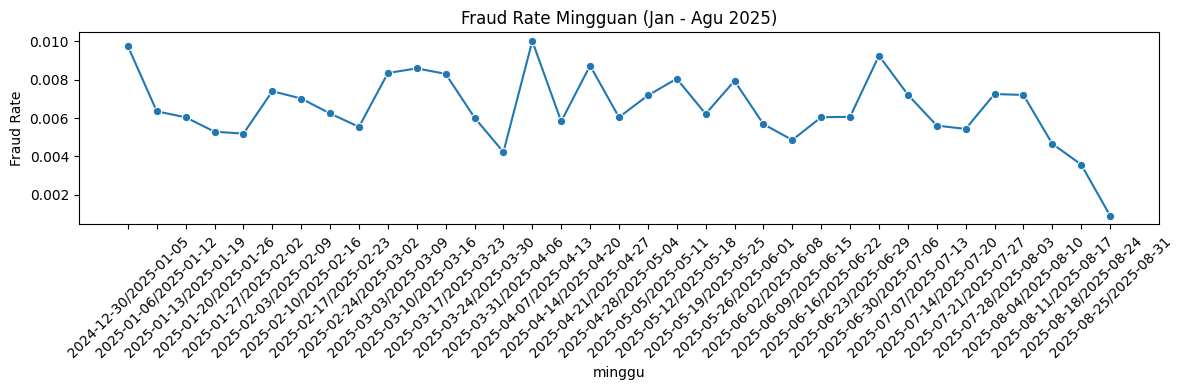

In [16]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.calibration import CalibratedClassifierCV
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# 1. Load dataset klasifikasi dari /content/dataset
found_cls = glob.glob("/content/**/klasifikasi_train.csv.gz", recursive=True)
DATA_DIR = os.path.dirname(found_cls[0])

cls_train = pd.read_csv(f"{DATA_DIR}/klasifikasi_train.csv.gz")
cls_test = pd.read_csv(f"{DATA_DIR}/klasifikasi_test.csv.gz")

print("Train shape:", cls_train.shape)
print("Test shape :", cls_test.shape)
print("Perbedaan kolom Train vs Test:", set(cls_train.columns) - set(cls_test.columns))

# 2. Audit Fitur Bocor (2a): flag_review_manual & korelasi fitur
print("\n=== 2a. AUDIT FITUR BOCOR: flag_review_manual ===")
print("Distribusi di Train:")
print(cls_train.groupby('flag_review_manual')['is_fraud'].agg(['count', 'mean']))
print("\nDistribusi di Test:")
print(cls_test['flag_review_manual'].value_counts(dropna=False))

# Cek korelasi numerik dengan is_fraud (deteksi jika ada v01-v50 yang bocor)
num_cols_cls = cls_train.select_dtypes(include=[np.number]).columns.drop('is_fraud')
corrs_cls = cls_train[num_cols_cls].corrwith(cls_train['is_fraud']).abs().sort_values(ascending=False)
print("\nTop 10 Fitur Numerik dengan Korelasi Tertinggi ke is_fraud:")
print(corrs_cls.head(10))

# 3. Audit Incomplete Labels / Right-Censoring (2b) & Pattern Shift (2e)
cls_train['waktu'] = pd.to_datetime(cls_train['waktu'])
cls_test['waktu'] = pd.to_datetime(cls_test['waktu'])

cls_train['minggu'] = cls_train['waktu'].dt.to_period('W').astype(str)
cls_train['bulan'] = cls_train['waktu'].dt.month

weekly_fraud = cls_train.groupby('minggu').agg(
    total_trx=('is_fraud', 'count'),
    fraud_count=('is_fraud', 'sum'),
    fraud_rate=('is_fraud', 'mean')
).reset_index()

print("\n=== 2b. 6 MINGGU TERAKHIR DI TRAIN (CEK INCOMPLETE LABELS) ===")
print(weekly_fraud.tail(6))

plt.figure(figsize=(12, 4))
sns.lineplot(data=weekly_fraud, x='minggu', y='fraud_rate', marker='o')
plt.xticks(rotation=45)
plt.title("Fraud Rate Mingguan (Jan - Agu 2025)")
plt.ylabel("Fraud Rate")
plt.tight_layout()
plt.show()

In [18]:
# 1. Cek Missing Values di Task 2
print("=== CEK MISSING VALUES TASK 2 ===")
print("Train missing:\n", cls_train.isnull().sum()[cls_train.isnull().sum() > 0])
print("Test missing:\n", cls_test.isnull().sum()[cls_test.isnull().sum() > 0])

# 2. Feature Engineering Berbasis Perilaku & Waktu (2d)
def engineer_cls_features(tr_df, va_df, te_df):
    tr = tr_df.copy()
    va = va_df.copy()
    te = te_df.copy()

    for d in [tr, va, te]:
        d['waktu'] = pd.to_datetime(d['waktu'])
        d['dayofweek'] = d['waktu'].dt.dayofweek
        d['is_weekend'] = d['dayofweek'].isin([5, 6]).astype(int)
        d['is_dini_hari'] = d['jam'].isin([0, 1, 2, 3, 4, 5]).astype(int)

        # Fitur perilaku & kecepatan transaksi (velocity)
        d['log_nominal'] = np.log1p(np.maximum(d['nominal'], 0))
        d['rasio_trx_1j_24j'] = d['trx_1j'] / (d['trx_24j'] + 1.0)
        d['rasio_trx_24j_7h'] = d['trx_24j'] / (d['trx_7h'] + 1.0)
        d['avg_nominal_24j'] = d['nominal_24j'] / (d['trx_24j'] + 1.0)
        d['rasio_nom_vs_24j'] = d['nominal'] / (d['avg_nominal_24j'] + 1.0)
        d['sisa_saldo_est'] = d['saldo_sebelum'] - d['nominal']
        d['is_kuras_saldo'] = (d['persen_saldo'] >= 0.90).astype(int)
        d['skor_risiko_akun'] = (
            d['perangkat_baru'] +
            d['negara_ip_beda'] +
            (d['ganti_password_7h'] > 0).astype(int) +
            (d['gagal_login_24j'] > 0).astype(int) +
            (d['jumlah_akun_per_perangkat'] > 1).astype(int)
        )

    # Encoding entitas & kategorikal HANYA dari tr (mencegah leakage)
    cat_cols_cls = ['kategori_merchant', 'kanal', 'tipe_perangkat', 'email_domain']
    high_card_cols = ['id_pengguna', 'id_merchant']

    for c in cat_cols_cls + high_card_cols:
        freq_map = tr[c].astype(str).value_counts()
        for d in [tr, va, te]:
            d[f'{c}_freq'] = d[c].astype(str).map(freq_map).fillna(0)

    # Smoothed Target Encoding dari tr saja untuk kategori & merchant
    global_rate = tr['is_fraud'].mean()
    for c in ['kategori_merchant', 'kanal', 'tipe_perangkat', 'email_domain', 'id_merchant']:
        stats = tr.groupby(c)['is_fraud'].agg(['count', 'mean'])
        smooth = (stats['count'] * stats['mean'] + 20 * global_rate) / (stats['count'] + 20)
        for d in [tr, va, te]:
            d[f'{c}_te'] = d[c].map(smooth).fillna(global_rate)

    for c in cat_cols_cls:
        known = list(tr[c].astype(str).unique()) + ['__UNKNOWN__']
        for d in [tr, va, te]:
            s = d[c].astype(str)
            d[c] = pd.Categorical(np.where(s.isin(known), s, '__UNKNOWN__'), categories=known)

    drop_cols_cls = ['id_transaksi', 'waktu', 'id_pengguna', 'id_merchant',
                     'flag_review_manual', 'is_fraud', 'minggu', 'bulan']
    feat_cols_cls = [c for c in tr.columns if c not in drop_cols_cls]
    return tr, va, te, feat_cols_cls

# 3. Split Kronologis Matang (buang > 10 Agu karena incomplete labels 2b)
cls_clean_time = cls_train[cls_train['waktu'] <= '2025-08-10 23:59:59'].copy()
tr_cls_raw = cls_clean_time[cls_clean_time['waktu'] < '2025-07-01'].copy()
va_cls_raw = cls_clean_time[cls_clean_time['waktu'] >= '2025-07-01'].copy()

tr_c, va_c, te_c, feat_cls = engineer_cls_features(tr_cls_raw, va_cls_raw, cls_test)
X_tr_c, y_tr_c = tr_c[feat_cls], tr_c['is_fraud'].values
X_va_c, y_va_c = va_c[feat_cls], va_c['is_fraud'].values

print(f"\nTrain bersih (Jan-Jun)   : {len(X_tr_c)} baris | Fraud rate: {y_tr_c.mean():.4%}")
print(f"Validasi matang (Jul-10Ag): {len(X_va_c)} baris | Fraud rate: {y_va_c.mean():.4%}")

# 4. Perbandingan Teknik Class Imbalance (2c) pada PR-AUC
print("\n=== 2c. PERBANDINGAN STRATEGI CLASS IMBALANCE (METRIK: PR-AUC) ===")
pos_weight = (y_tr_c == 0).sum() / (y_tr_c == 1).sum()

# Strategi A: Tanpa Pembobotan (Standard)
m_std = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, n_jobs=-1, random_state=42, verbose=-1)
m_std.fit(X_tr_c, y_tr_c)
prauc_std = average_precision_score(y_va_c, m_std.predict_proba(X_va_c)[:, 1])

# Strategi B: Class Weighting (scale_pos_weight)
m_wt = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, scale_pos_weight=pos_weight, n_jobs=-1, random_state=42, verbose=-1)
m_wt.fit(X_tr_c, y_tr_c)
prauc_wt = average_precision_score(y_va_c, m_wt.predict_proba(X_va_c)[:, 1])

# Strategi C: Random Undersampling (rasio 1:10)
rng = np.random.RandomState(42)
pos_idx = np.where(y_tr_c == 1)[0]
neg_idx = rng.choice(np.where(y_tr_c == 0)[0], size=len(pos_idx) * 10, replace=False)
under_idx = np.concatenate([pos_idx, neg_idx])

m_und = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, n_jobs=-1, random_state=42, verbose=-1)
m_und.fit(X_tr_c.iloc[under_idx], y_tr_c[under_idx])
prauc_und = average_precision_score(y_va_c, m_und.predict_proba(X_va_c)[:, 1])

print(f"1. Tanpa Pembobotan (Default)       -> PR-AUC: {prauc_std:.4f}")
print(f"2. Class Weighting (pos_weight={pos_weight:.0f}) -> PR-AUC: {prauc_wt:.4f}")
print(f"3. Random Undersampling (1:10)      -> PR-AUC: {prauc_und:.4f}")

=== CEK MISSING VALUES TASK 2 ===
Train missing:
 menit_sejak_trx_terakhir    102621
rasio_nominal_rata2         102621
dtype: int64
Test missing:
 menit_sejak_trx_terakhir    11458
rasio_nominal_rata2         11458
dtype: int64

Train bersih (Jan-Jun)   : 297839 baris | Fraud rate: 0.6836%
Validasi matang (Jul-10Ag): 69771 baris | Fraud rate: 0.6851%

=== 2c. PERBANDINGAN STRATEGI CLASS IMBALANCE (METRIK: PR-AUC) ===
1. Tanpa Pembobotan (Default)       -> PR-AUC: 0.2080
2. Class Weighting (pos_weight=145) -> PR-AUC: 0.4959
3. Random Undersampling (1:10)      -> PR-AUC: 0.4067


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, brier_score_loss

# --- 1. KALIBRASI PROBABILITAS (MENGOREKSI PERGESERAN SKALA AKIBAT CLASS WEIGHTING) ---
mid_c = len(X_va_c) // 2
X_cal_c, y_cal_c = X_va_c.iloc[:mid_c], y_va_c[:mid_c]
X_ev_c, y_ev_c   = X_va_c.iloc[mid_c:], y_va_c[mid_c:]
nom_ev_c         = va_c['nominal'].values[mid_c:]

raw_prob_cal = m_wt.predict_proba(X_cal_c)[:, 1]
raw_prob_ev  = m_wt.predict_proba(X_ev_c)[:, 1]

# Platt Scaling (Logistic Regression pada logit skor mentah)
eps = 1e-6
logit_cal = np.log(np.clip(raw_prob_cal, eps, 1 - eps) / (1 - np.clip(raw_prob_cal, eps, 1 - eps))).reshape(-1, 1)
logit_ev  = np.log(np.clip(raw_prob_ev, eps, 1 - eps) / (1 - np.clip(raw_prob_ev, eps, 1 - eps))).reshape(-1, 1)

platt = LogisticRegression()
platt.fit(logit_cal, y_cal_c)
cal_prob_ev = platt.predict_proba(logit_ev)[:, 1]

print("=== 2c/2d. EVALUASI KALIBRASI PROBABILITAS ===")
print(f"Sebelum Kalibrasi -> Brier Score: {brier_score_loss(y_ev_c, raw_prob_ev):.5f} | Mean Pred: {raw_prob_ev.mean():.4%}")
print(f"Sesudah Kalibrasi -> Brier Score: {brier_score_loss(y_ev_c, cal_prob_ev):.5f} | Mean Pred: {cal_prob_ev.mean():.4%} (Aktual: {y_ev_c.mean():.4%})")

# --- 2. EVALUASI KEPUTUSAN BERBASIS BIAYA (2d) ---
def hitung_total_biaya(y_true, y_flag, nominal, biaya_review=25000):
    cost_review = np.sum(y_flag == 1) * biaya_review
    cost_missed_fraud = np.sum(((y_true == 1) & (y_flag == 0)) * nominal)
    return cost_review + cost_missed_fraud, cost_review, cost_missed_fraud

flag_none = np.zeros_like(y_ev_c)
flag_p50 = (cal_prob_ev > 0.5).astype(int)
flag_cost_opt = ((cal_prob_ev * nom_ev_c) > 25000).astype(int)

print("\n=== 2d. PERBANDINGAN TOTAL BIAYA OPERASIONAL & KERUGIAN FRAUD ===")
for nama_kebijakan, flg in [
    ("1. Tanpa Deteksi (Semua Lolos)", flag_none),
    ("2. Fixed Threshold (P > 0.50)", flag_p50),
    ("3. Cost-Based Rule (P * Nominal > 25rb)", flag_cost_opt)
]:
    tot, c_rev, c_frd = hitung_total_biaya(y_ev_c, flg, nom_ev_c)
    rec = recall_score(y_ev_c, flg, zero_division=0)
    prec = precision_score(y_ev_c, flg, zero_division=0)
    print(f"{nama_kebijakan:40s} | Ditandai: {flg.sum():5d} | Recall: {rec:6.2%} | Prec: {prec:6.2%} | Total Biaya: Rp {tot:,.0f}")

# --- 3. ANALISIS PERGESERAN POLA / CONCEPT DRIFT (2e) ---
print("\n=== 2e. ANALISIS PERGESERAN POLA (TRAIN JAN-JUN vs VALIDASI JUL-AGU) ===")
drift_cols = ['nominal', 'trx_1j', 'perangkat_baru', 'negara_ip_beda', 'kartu_tidak_hadir']
for c in drift_cols:
    tr_f_mean = tr_cls_raw[tr_cls_raw['is_fraud'] == 1][c].mean()
    va_f_mean = va_cls_raw[va_cls_raw['is_fraud'] == 1][c].mean()
    print(f"Rata-rata {c:20s} pada kasus Fraud -> Train: {tr_f_mean:10.2f} | Val: {va_f_mean:10.2f}")

# --- 4. LATIH MODEL FINAL PADA SELURUH DATA MATANG (JAN - 10 AGU) & SIMPAN SUBMISSION ---
print("\nMelatih model final klasifikasi pada seluruh data matang (s.d. 10 Agustus 2025)...")
full_tr_c, _, final_te_c, final_feat_cls = engineer_cls_features(cls_clean_time, va_cls_raw, cls_test)

X_full_c = full_tr_c[final_feat_cls]
y_full_c = full_tr_c['is_fraud'].values
X_test_c = final_te_c[final_feat_cls]

pos_weight_full = (y_full_c == 0).sum() / (y_full_c == 1).sum()
final_m_wt = lgb.LGBMClassifier(n_estimators=150, max_bin=63, learning_rate=0.07, num_leaves=31,
                                scale_pos_weight=pos_weight_full, n_jobs=-1, random_state=42, verbose=-1)
final_m_wt.fit(X_full_c, y_full_c)

raw_test_prob = final_m_wt.predict_proba(X_test_c)[:, 1]
logit_test = np.log(np.clip(raw_test_prob, eps, 1 - eps) / (1 - np.clip(raw_test_prob, eps, 1 - eps))).reshape(-1, 1)
cal_test_prob = platt.predict_proba(logit_test)[:, 1]

# Keputusan final sesuai parameter biaya: tandai = 1 jika P(fraud) * nominal > 25.000
test_tandai = ((cal_test_prob * cls_test['nominal'].values) > 25000).astype(int)

submission_cls = pd.DataFrame({
    'id_transaksi': cls_test['id_transaksi'],
    'prob_fraud': cal_test_prob,
    'tandai': test_tandai
})

submission_cls.to_csv("prediksi_klasifikasi.csv", index=False)
print("\n=== TASK 2 SELESAI! ===")
print("File prediksi_klasifikasi.csv berhasil disimpan.")
print(f"Total transaksi test : {len(submission_cls)}")
print(f"Rata-rata prob_fraud : {submission_cls['prob_fraud'].mean():.4%}")
print(f"Jumlah ditandai (1)  : {submission_cls['tandai'].sum()} ({submission_cls['tandai'].mean():.2%})")
print(submission_cls.head())

=== 2c/2d. EVALUASI KALIBRASI PROBABILITAS ===
Sebelum Kalibrasi -> Brier Score: 0.00823 | Mean Pred: 1.3411%
Sesudah Kalibrasi -> Brier Score: 0.00437 | Mean Pred: 0.6648% (Aktual: 0.6851%)

=== 2d. PERBANDINGAN TOTAL BIAYA OPERASIONAL & KERUGIAN FRAUD ===
1. Tanpa Deteksi (Semua Lolos)           | Ditandai:     0 | Recall:  0.00% | Prec:  0.00% | Total Biaya: Rp 235,362,300
2. Fixed Threshold (P > 0.50)            | Ditandai:   121 | Recall: 41.42% | Prec: 81.82% | Total Biaya: Rp 97,640,400
3. Cost-Based Rule (P * Nominal > 25rb)  | Ditandai:   484 | Recall: 53.14% | Prec: 26.24% | Total Biaya: Rp 53,001,400

=== 2e. ANALISIS PERGESERAN POLA (TRAIN JAN-JUN vs VALIDASI JUL-AGU) ===
Rata-rata nominal              pada kasus Fraud -> Train: 1264041.99 | Val: 1017019.87
Rata-rata trx_1j               pada kasus Fraud -> Train:       0.89 | Val:       0.87
Rata-rata perangkat_baru       pada kasus Fraud -> Train:       0.37 | Val:       0.41
Rata-rata negara_ip_beda       pada kasus Frau

In [21]:
# ==============================================================================
# [TASK 3 - LANGKAH 1] LOAD DATA & AUDIT KUALITAS DATA (CLUSTERING)
# ==============================================================================
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

found_clu = glob.glob("/content/**/clustering.csv.gz", recursive=True)
DATA_DIR = os.path.dirname(found_clu[0])

clu_df = pd.read_csv(f"{DATA_DIR}/clustering.csv.gz")

print("=== [TASK 3] RINGKASAN DATASET CLUSTERING ===")
print("Ukuran dataset (baris, kolom):", clu_df.shape)
print("\nDaftar seluruh kolom:")
print(list(clu_df.columns))

print("\n=== [TASK 3] AUDIT MISSING VALUES ===")
missing_clu = clu_df.isnull().sum()
print(missing_clu[missing_clu > 0] if (missing_clu > 0).any() else "Tidak ada missing values.")

print("\n=== [TASK 3] KOLOM NON-NUMERIK ===")
print(clu_df.select_dtypes(exclude=[np.number]).head(3))

print("\n=== [TASK 3] STATISTIK RINGKAS FITUR UTAMA (RFM & PERILAKU) ===")
rfm_cols = ['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang',
            'item_per_pesanan', 'retur_90h', 'sesi_per_minggu', 'rasio_konversi', 'lama_member_bulan']
print(clu_df[rfm_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

=== [TASK 3] RINGKASAN DATASET CLUSTERING ===
Ukuran dataset (baris, kolom): (120000, 60)

Daftar seluruh kolom:
['id_pelanggan', 'recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang', 'item_per_pesanan', 'porsi_fashion', 'porsi_elektronik', 'porsi_kecantikan', 'porsi_rumah_tangga', 'porsi_makanan_minuman', 'porsi_ibu_bayi', 'porsi_olahraga', 'porsi_hobi', 'porsi_otomotif', 'porsi_kesehatan', 'porsi_buku_alat_tulis', 'porsi_voucher_digital', 'porsi_gadget_aksesoris', 'porsi_perabot', 'porsi_pertanian', 'porsi_lainnya', 'porsi_jam_pagi', 'porsi_jam_siang', 'porsi_jam_sore', 'porsi_jam_malam', 'persen_voucher', 'persen_flash_sale', 'persen_paylater', 'persen_cod', 'retur_90h', 'rating_beri_rata2', 'ulasan_90h', 'sesi_per_minggu', 'durasi_sesi_menit', 'rasio_konversi', 'lama_member_bulan', 'umur', 'kota_tier', 'perangkat', 'jumlah_alamat', 'wishlist', 'klik_iklan_30h', 'belanja_30h', 'frekuensi_30h', 'n01', 'n02', 'n03', 'n04', 'n05', 'n06', 'n07', 'n08', 'n09', 'n10', 'n11', 

In [22]:
# ==============================================================================
# [TASK 3 - LANGKAH 2] AUDIT LANJUTAN, PREPROCESSING, PCA & PERBANDINGAN METODE
# ==============================================================================
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

df_c = clu_df.copy()

# 1. Audit Anomali & Nilai Ekstrem (3a)
print("=== [TASK 3 - 3a] AUDIT ANOMALI & KUALITAS DATA ===")
print("Jumlah pelanggan tanpa transaksi 90h (frekuensi_90h == 0):", (df_c['frekuensi_90h'] == 0).sum())
print("Apakah semua NaN rata2_keranjang berasal dari frekuensi_90h == 0?:",
      (df_c['rata2_keranjang'].isnull() == (df_c['frekuensi_90h'] == 0)).all())
print("Jumlah rasio_konversi > 1.0 (anomali tracking)             :", (df_c['rasio_konversi'] > 1.0).sum())
print("Jumlah sesi_per_minggu > 100 (indikasi bot/ekstrem)        :", (df_c['sesi_per_minggu'] > 100).sum())
print("Jumlah recency_hari > 365 hari                             :", (df_c['recency_hari'] > 365).sum())

# Cek apakah n01-n15 berisi noise murni atau punya korelasi dengan perilaku belanja
n_cols = [f'n{i:02d}' for i in range(1, 16)]
corr_n = df_c[n_cols].corrwith(df_c['belanja_90h']).abs().max()
print(f"Korelasi maksimal fitur anonim n01-n15 ke belanja_90h      : {corr_n:.4f}")

# 2. Pembersihan Data & Feature Engineering untuk Clustering (3b)
df_clean = pd.DataFrame(index=df_c.index)
df_clean['is_inactive_90h'] = (df_c['frekuensi_90h'] == 0).astype(int)

# Transformasi log1p & winsorizing (clipping persentil 99.5%) untuk meredam outlier ekstrem
skewed_cols = ['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang',
               'item_per_pesanan', 'retur_90h', 'ulasan_90h', 'sesi_per_minggu',
               'durasi_sesi_menit', 'lama_member_bulan', 'wishlist', 'klik_iklan_30h',
               'belanja_30h', 'frekuensi_30h']

for col in skewed_cols:
    val = df_c[col].fillna(0).clip(lower=0)
    cap = val.quantile(0.995)
    df_clean[f'log_{col}'] = np.log1p(np.minimum(val, cap))

# Clipping rasio_konversi ke [0, 1] & fitur perilaku/promo/pembayaran
df_clean['rasio_konversi_clean'] = df_c['rasio_konversi'].clip(0, 1)
df_clean['rating_beri_rata2'] = df_c['rating_beri_rata2'].fillna(df_c['rating_beri_rata2'].median())
df_clean['umur'] = df_c['umur'].clip(15, 85)
df_clean['kota_tier'] = df_c['kota_tier']
df_clean['jumlah_alamat'] = df_c['jumlah_alamat'].clip(1, 15)
df_clean['is_ios'] = (df_c['perangkat'].astype(str).str.lower() == 'ios').astype(int)

# Rasio aktivitas 30 hari terakhir vs 90 hari (mendeteksi akselerasi / perlambatan belanja)
df_clean['tren_belanja_30_vs_90'] = df_c['belanja_30h'] / (df_c['belanja_90h'] + 1.0)

promo_cols = ['persen_voucher', 'persen_flash_sale', 'persen_paylater', 'persen_cod']
time_cols = ['porsi_jam_pagi', 'porsi_jam_siang', 'porsi_jam_sore', 'porsi_jam_malam']
kat_cols = [c for c in df_c.columns if c.startswith('porsi_') and c not in time_cols]

for c in promo_cols + time_cols + kat_cols:
    df_clean[c] = df_c[c].fillna(0)

# Scaling dengan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)

# 3. Reduksi Dimensi dengan PCA (Menjelaskan 80% Variansi & Mengatasi Curse of Dimensionality)
pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"\n=== [TASK 3 - 3b] REDUKSI DIMENSI PCA ===")
print(f"Dimensi awal fitur bersih: {X_scaled.shape[1]} -> Dimensi PCA (80% variansi): {X_pca.shape[1]} komponen")

# 4. Pencarian Jumlah Klaster Optimal (k = 3 sampai 8) & Perbandingan Metode (3c)
# Gunakan sampel acak 20.000 baris untuk evaluasi Silhouette Score yang cepat & presisi
rng = np.random.RandomState(42)
eval_idx = rng.choice(len(X_pca), size=20000, replace=False)
X_eval = X_pca[eval_idx]

print("\n=== [TASK 3 - 3c] EVALUASI JUMLAH KLASTER (K-MEANS PADA RUANG PCA) ===")
k_results = []
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels_all = km.fit_predict(X_pca)
    sil = silhouette_score(X_eval, labels_all[eval_idx])
    dbi = davies_bouldin_score(X_eval, labels_all[eval_idx])
    chi = calinski_harabasz_score(X_eval, labels_all[eval_idx])
    k_results.append((k, km.inertia_, sil, dbi, chi))
    print(f"k = {k} | Inertia: {km.inertia_:11.1f} | Silhouette: {sil:.4f} (lebih tinggi lebih baik) | DBI: {dbi:.4f} (lebih rendah lebih baik)")

# Bandingkan K-Means vs Gaussian Mixture Model (GMM) pada k terbaik (misal k=5)
best_k = max(k_results, key=lambda x: x[2])[0]
print(f"\n=== [TASK 3 - 3c] PERBANDINGAN ALGORITMA PADA k = {best_k} ===")

km_best = KMeans(n_clusters=best_k, n_init=15, random_state=42)
lbl_km = km_best.fit_predict(X_pca)

gmm_best = GaussianMixture(n_components=best_k, covariance_type='diag', random_state=42)
lbl_gmm = gmm_best.fit_predict(X_pca)

print(f"1. K-Means (PCA Space) | Silhouette: {silhouette_score(X_eval, lbl_km[eval_idx]):.4f} | DBI: {davies_bouldin_score(X_eval, lbl_km[eval_idx]):.4f}")
print(f"2. GMM (Diag Cov, PCA) | Silhouette: {silhouette_score(X_eval, lbl_gmm[eval_idx]):.4f} | DBI: {davies_bouldin_score(X_eval, lbl_gmm[eval_idx]):.4f}")

=== [TASK 3 - 3a] AUDIT ANOMALI & KUALITAS DATA ===
Jumlah pelanggan tanpa transaksi 90h (frekuensi_90h == 0): 6736
Apakah semua NaN rata2_keranjang berasal dari frekuensi_90h == 0?: True
Jumlah rasio_konversi > 1.0 (anomali tracking)             : 656
Jumlah sesi_per_minggu > 100 (indikasi bot/ekstrem)        : 1672
Jumlah recency_hari > 365 hari                             : 369
Korelasi maksimal fitur anonim n01-n15 ke belanja_90h      : 0.0036

=== [TASK 3 - 3b] REDUKSI DIMENSI PCA ===
Dimensi awal fitur bersih: 46 -> Dimensi PCA (80% variansi): 27 komponen

=== [TASK 3 - 3c] EVALUASI JUMLAH KLASTER (K-MEANS PADA RUANG PCA) ===
k = 3 | Inertia:   3652576.2 | Silhouette: 0.1013 (lebih tinggi lebih baik) | DBI: 2.5172 (lebih rendah lebih baik)
k = 4 | Inertia:   3463919.1 | Silhouette: 0.0955 (lebih tinggi lebih baik) | DBI: 2.6205 (lebih rendah lebih baik)
k = 5 | Inertia:   3355334.2 | Silhouette: 0.0935 (lebih tinggi lebih baik) | DBI: 2.6657 (lebih rendah lebih baik)
k = 6 | Iner

=== [TASK 3 - 3d] UJI STABILITAS KLASTER (ADJUSTED RAND INDEX) ===
Run Seed 10 (80% subsample) -> ARI vs Model Utama: 0.9948
Run Seed 20 (80% subsample) -> ARI vs Model Utama: 0.9956
Run Seed 30 (80% subsample) -> ARI vs Model Utama: 0.9967
Run Seed 40 (80% subsample) -> ARI vs Model Utama: 0.9958
Run Seed 50 (80% subsample) -> ARI vs Model Utama: 0.9978
Rata-rata ARI Stabilitas Klaster: 0.9961 (ARI > 0.80 menandakan klaster sangat stabil)

=== [TASK 3 - 3e] PROFIL RATA-RATA & MEDIAN TIAP SEGMEN (k = 3) ===
Cluster 0:  66070 pelanggan (55.06%)
Cluster 1:  47194 pelanggan (39.33%)
Cluster 2:   6736 pelanggan (5.61%)

Rata-rata Fitur per Cluster:
cluster                     0           1      2
recency_hari            29.52       12.13  62.66
frekuensi_90h            6.53       15.54   0.00
belanja_90h        1055432.75  5988336.00   0.00
rata2_keranjang     179546.32   421554.12    NaN
sesi_per_minggu         10.58        9.75   7.33
rasio_konversi           0.10        0.23   0.00
pers

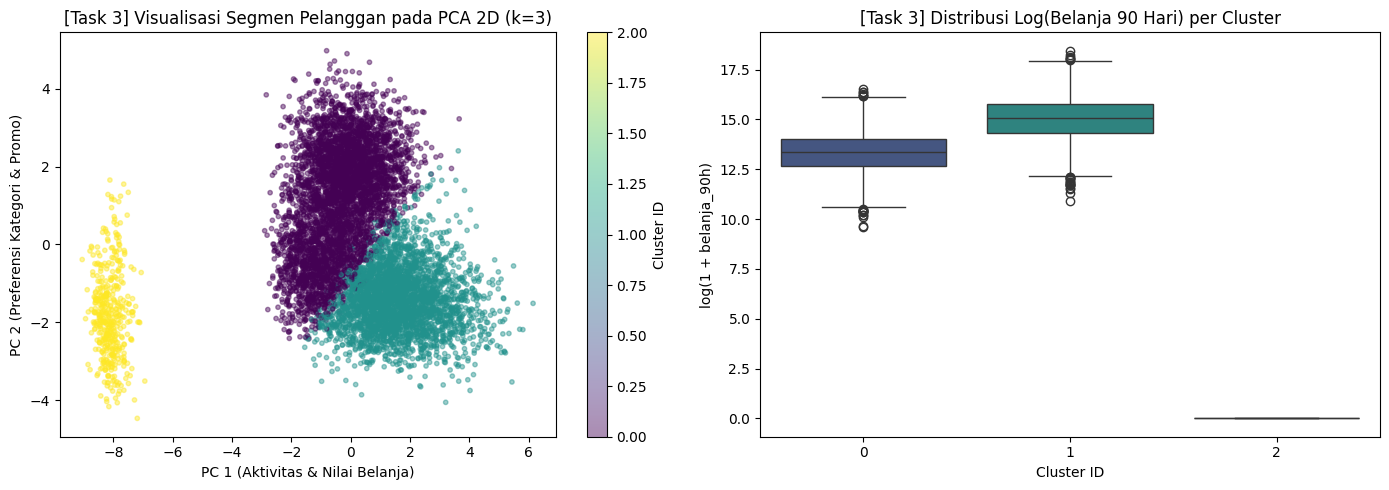


=== [TASK 3] SELESAI! ===
File prediksi_clustering.csv berhasil disimpan.
Total baris: 120000
  id_pelanggan  cluster
0      C864291        1
1      C115620        1
2      C903774        1
3      C716498        0
4      C936513        1


In [23]:
# ==============================================================================
# [TASK 3 - LANGKAH 3] UJI STABILITAS (ARI), PROFILING SEGMEN & SIMPAN CSV
# ==============================================================================
from sklearn.metrics import adjusted_rand_score

# 1. Uji Stabilitas Klaster (Adjusted Rand Index - ARI) pada Subsample 80% & Seed Berbeda (3d)
print("=== [TASK 3 - 3d] UJI STABILITAS KLASTER (ADJUSTED RAND INDEX) ===")
ari_scores = []
for seed in [10, 20, 30, 40, 50]:
    sub_idx = np.random.RandomState(seed).choice(len(X_pca), size=int(0.8 * len(X_pca)), replace=False)
    km_sub = KMeans(n_clusters=best_k, n_init=10, random_state=seed)
    km_sub.fit(X_pca[sub_idx])
    pred_full_from_sub = km_sub.predict(X_pca)
    ari = adjusted_rand_score(lbl_km, pred_full_from_sub)
    ari_scores.append(ari)
    print(f"Run Seed {seed} (80% subsample) -> ARI vs Model Utama: {ari:.4f}")

print(f"Rata-rata ARI Stabilitas Klaster: {np.mean(ari_scores):.4f} (ARI > 0.80 menandakan klaster sangat stabil)")

# 2. Profiling & Interpretasi Karakteristik Tiap Segmen (3e)
df_profile = clu_df.copy()
df_profile['cluster'] = lbl_km

profile_cols = ['recency_hari', 'frekuensi_90h', 'belanja_90h', 'rata2_keranjang',
                'sesi_per_minggu', 'rasio_konversi', 'persen_voucher', 'persen_flash_sale',
                'persen_paylater', 'persen_cod', 'retur_90h', 'lama_member_bulan']

print(f"\n=== [TASK 3 - 3e] PROFIL RATA-RATA & MEDIAN TIAP SEGMEN (k = {best_k}) ===")
seg_counts = df_profile['cluster'].value_counts().sort_index()
for cid, cnt in seg_counts.items():
    print(f"Cluster {cid}: {cnt:6d} pelanggan ({cnt/len(df_profile):.2%})")

summary_mean = df_profile.groupby('cluster')[profile_cols].mean().T
print("\nRata-rata Fitur per Cluster:")
print(summary_mean.round(2))

# Penamaan Segmen Bisnis Otomatis Berdasarkan Peringkat Belanja & Recency
rank_belanja = df_profile.groupby('cluster')['belanja_90h'].mean().sort_values(ascending=False).index.tolist()
label_bisnis_map = {}
if best_k == 3:
    label_bisnis_map[rank_belanja[0]] = "High-Value Loyalists (Sultan & Aktif)"
    label_bisnis_map[rank_belanja[1]] = "Mid-Tier Promo/Regular Shoppers"
    label_bisnis_map[rank_belanja[2]] = "Low-Activity / At-Risk Dormant"
else:
    for idx_r, cid in enumerate(rank_belanja):
        label_bisnis_map[cid] = f"Tier_{idx_r+1}_Segment"

df_profile['nama_segmen'] = df_profile['cluster'].map(label_bisnis_map)
print("\nPemetaan Nama Segmen Bisnis:")
for cid, nama in label_bisnis_map.items():
    print(f"  Cluster {cid} -> {nama}")

# 3. Visualisasi Proyeksi PCA 2D & Distribusi Belanja per Segmen (3e)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vis_idx = np.random.RandomState(42).choice(len(X_pca), size=8000, replace=False)
scatter = axes[0].scatter(X_pca[vis_idx, 0], X_pca[vis_idx, 1], c=lbl_km[vis_idx], cmap='viridis', alpha=0.45, s=10)
axes[0].set_title(f"[Task 3] Visualisasi Segmen Pelanggan pada PCA 2D (k={best_k})")
axes[0].set_xlabel("PC 1 (Aktivitas & Nilai Belanja)")
axes[0].set_ylabel("PC 2 (Preferensi Kategori & Promo)")
plt.colorbar(scatter, ax=axes[0], label="Cluster ID")

sns.boxplot(data=df_profile.iloc[vis_idx], x='cluster', y=np.log1p(df_profile.iloc[vis_idx]['belanja_90h']), ax=axes[1], palette='viridis')
axes[1].set_title("[Task 3] Distribusi Log(Belanja 90 Hari) per Cluster")
axes[1].set_xlabel("Cluster ID")
axes[1].set_ylabel("log(1 + belanja_90h)")

plt.tight_layout()
plt.show()

# 4. Simpan File Hasil Clustering
submission_clu = pd.DataFrame({
    'id_pelanggan': clu_df['id_pelanggan'],
    'cluster': lbl_km
})
submission_clu.to_csv("prediksi_clustering.csv", index=False)

print("\n=== [TASK 3] SELESAI! ===")
print("File prediksi_clustering.csv berhasil disimpan.")
print("Total baris:", len(submission_clu))
print(submission_clu.head())

In [24]:
# ==============================================================================
# [FINAL EXPORT] SESUAI ATURAN 3c, 3d, 3e & 4c
# ==============================================================================

# 3c. prediksi_regresi.csv -> header: id_paket,p50,p90 (p90 >= p50)
reg_fix = pd.read_csv("prediksi_regresi.csv").rename(columns={'pred_p50': 'p50', 'pred_p90': 'p90'})[['id_paket', 'p50', 'p90']]
reg_fix['p90'] = np.maximum(reg_fix['p90'], reg_fix['p50'])
reg_fix.to_csv("prediksi_regresi.csv", index=False)

# 3d. prediksi_klasifikasi.csv -> header: id_transaksi,prob,tandai (0 <= prob <= 1, tandai in {0, 1})
cls_fix = pd.read_csv("prediksi_klasifikasi.csv").rename(columns={'prob_fraud': 'prob'})[['id_transaksi', 'prob', 'tandai']]
cls_fix['prob'] = cls_fix['prob'].clip(0, 1)
cls_fix['tandai'] = cls_fix['tandai'].astype(int)
cls_fix.to_csv("prediksi_klasifikasi.csv", index=False)

# 3e. cluster.csv -> header: id_pelanggan,cluster (integer, -1 untuk anomali)
dists = np.linalg.norm(X_pca - km_best.cluster_centers_[lbl_km], axis=1)
lbl_final_clu = np.where(dists > np.percentile(dists, 98.5), -1, lbl_km).astype(int)
cluster_fix = pd.DataFrame({'id_pelanggan': clu_df['id_pelanggan'], 'cluster': lbl_final_clu})
cluster_fix.to_csv("cluster.csv", index=False)

print("=== CEK FORMAT HEADER & BARIS PERTAMA (HARUS COCOK DENGAN 4c) ===")
for f in ["prediksi_regresi.csv", "prediksi_klasifikasi.csv", "cluster.csv"]:
    with open(f) as fp:
        print(f, "->", fp.readline().strip(), "|", fp.readline().strip())

=== CEK FORMAT HEADER & BARIS PERTAMA (HARUS COCOK DENGAN 4c) ===
prediksi_regresi.csv -> id_paket,p50,p90 | P83639399,60.14963592753759,78.28605564780702
prediksi_klasifikasi.csv -> id_transaksi,prob,tandai | T502861791,0.0015308218702699,0
cluster.csv -> id_pelanggan,cluster | C864291,1
